# Задание_1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import re

# Load data
df = pd.read_csv('IT_Life_10000x1000_FINAL.csv', encoding='utf-8-sig')

mapping = {'Н': 'N'}

my_letter = 'Н' 
latin_prefix = mapping[my_letter]

condition = df['nickname'].str.startswith(my_letter) | df['nickname'].str.startswith(latin_prefix)

df = df[condition].copy()
print(f"Variant rows: {len(df)}")
df.head(10)

Variant rows: 334


,nickname,age_years,height_cm,weight_kg,bmi,years_in_it,salary_rub_month,work_hours_week,sleep_hours_day,stress_score_0_100,...,social_group_chats_interactions_month,social_group_chats_satisfaction_0_10,social_online_forums_interactions_month,social_online_forums_satisfaction_0_10,social_collaborative_projects_interactions_month,social_collaborative_projects_satisfaction_0_10,last_repo_slug,online_community_team_id,cloud_archive_bytes_total,project_website_views_total
5,НочнойПарусСкиталец,18.0,165.8,47.0,17.11,0.0,132174.0,47.2,8.23,38,...,29.0,6.0,7.0,5.0,10.0,5.0,repo_02219,team_1068,3925029017613,13287484828
36,НочнойМуравейСкиталец,41.0,173.6,61.5,NaN,13.6,499949.0,50.0,7.89,38,...,6.0,NaN,20.0,8.0,NaN,NaN,repo_04746,team_0636,146859,11653519
45,НочнойБобёрСкиталец,28.0,173.4,81.8,NaN,4.5,185234.0,41.8,8.19,31,...,4.0,5.0,4.0,4.0,4.0,5.0,repo_03869,team_0435,343988,1193333476
52,НочнойЛисИскатель,36.0,166.8,49.9,17.95,14.1,677823.0,50.1,8.11,42,...,13.0,7.0,NaN,8.0,27.0,?,repo_01375,team_0214,5461501119621,26
57,НочнойЛемурСкиталец,36.0,177.4,86.7,NaN,11.3,815229.0,25.4,7.66,11,...,14.0,6.0,22.0,NaN,7.0,6.0,repo_00129,team_0085,193356,75210
178,НочнойКосмосСкиталец,NaN,168.2,94.2,33.30,16.3,274031.0,39.2,8.89,30,...,118.0,5.0,23.0,5.0,2.0,?,repo_02568,team_1200,267156556,120913238068
185,NeonRocketNavigator,26.0,161.0,57.9,22.31,3.3,212009.0,54.8,6.51,41,...,NaN,4.0,2.0,4.0,5.0,3.0,repo_00125,team_0356,18990970,507054132
206,NeonSailorNomad,18.0,167.2,42.0,15.02,0.0,101361.0,53.0,7.51,42,...,14.0,1.0,3.0,2.0,16.0,2.0,repo_01964,team_0054,61741073237815,647
214,NeonCosmosNavigator,35.0,159.5,68.7,27.01,12.9,NaN,61.9,6.23,55,...,12.0,3.0,14.0,5.0,8.0,3.0,repo_01831,team_1018,77078292375,52461394
216,NeonNeuronNomad,21.0,173.3,94.4,31.42,0.0,25692.0,60.8,6.80,55,...,46.0,NaN,6.0,7.0,7.0,5.0,repo_03937,team_0377,70807209975506,69


In [2]:
def classify(col: pd.Series, name: str):
    if col.is_unique and (col.dtype.kind in "iu" or name.lower().endswith("id")):
        return "identifier"
    if pd.api.types.is_numeric_dtype(col):
        return "numeric"
    if col.nunique(dropna=True) <= max(20, 0.05 * len(col)):
        return "categorical"
    return "categorical"  

kinds = {c: classify(df[c], c) for c in df.columns}

print(pd.Series(kinds).value_counts())          # counts per type

meaningful = [c for c, k in kinds.items() if k != "identifier"][:25]
df[meaningful].head()

numeric        973
categorical     27
identifier       1
Name: count, dtype: int64


,nickname,age_years,height_cm,weight_kg,bmi,years_in_it,salary_rub_month,work_hours_week,sleep_hours_day,stress_score_0_100,...,city,country_region,education_level,risk_attitude,primary_programming_language,preferred_os,salary_satisfaction_0_10,job_satisfaction_0_10,mental_energy_0_100,physical_energy_0_100
5,НочнойПарусСкиталец,18.0,165.8,47.0,17.11,0.0,132174.0,47.2,8.23,38,...,NaN,Казахстан,бакалавриат,высокий,C#,Linux,1,6.0,89,88.0
36,НочнойМуравейСкиталец,41.0,173.6,61.5,NaN,13.6,499949.0,50.0,7.89,38,...,Москва,Беларусь,NaN,низкий,Ruby,Windows,2,8.0,86,93.0
45,НочнойБобёрСкиталец,28.0,173.4,81.8,NaN,4.5,185234.0,41.8,8.19,31,...,Новосибирск,Европа,бакалавриат,NaN,PHP,NaN,4,NaN,89,94.0
52,НочнойЛисИскатель,36.0,166.8,49.9,17.95,14.1,677823.0,50.1,8.11,42,...,Санкт-Петербург,Европа,магистратура,низкий,Ruby,Windows,7,5.0,78,NaN
57,НочнойЛемурСкиталец,36.0,177.4,86.7,NaN,11.3,815229.0,25.4,7.66,11,...,Москва,Россия,бакалавриат,высокий,Ruby,Windows,4,8.0,100,99.0


In [3]:
def passport(col_name, dtype_label, units, valid_range):
    s = df[col_name]
    return {
        "feature": col_name,
        "type": dtype_label,           # int / float / category / datetime
        "units": units,                # "years", "RUB", "hours", ...
        "valid_range": valid_range,    # (min, max) you consider plausible
        "observed_min": s.min(),
        "observed_max": s.max(),
        "missing": s.isna().sum(),
    }

features = [
    passport("age_years",         "int",   "years",  (0, 60)),
    passport("height_cm",  "float", "cm",  (0, 190)),
    passport("salary_rub_month",      "float", "RUB",    (0, 10_000_000)),
    passport("sleep_hours_day", "float", "hours",  (0, 10)),
    passport("work_hours_week",    "float",   "hours",   (0, 80)),
    passport("years_in_it","flaot",  "years",  (0, 20.0)),
]

pd.DataFrame(features)

,feature,type,units,valid_range,observed_min,observed_max,missing
0,age_years,int,years,"(0, 60)",18.00,217.00,31
1,height_cm,float,cm,"(0, 190)",28.00,192.60,31
2,salary_rub_month,float,RUB,"(0, 10000000)",19144.00,2451759.00,19
3,sleep_hours_day,float,hours,"(0, 10)",4.85,9.59,0
4,work_hours_week,float,hours,"(0, 80)",12.00,87.10,4
5,years_in_it,flaot,years,"(0, 20.0)",0.00,33.90,36


In [4]:
num_cols = [c for c, k in kinds.items() if k == "numeric"]

stats = pd.DataFrame({
    "col":       num_cols,
    "min":       [df[c].min() for c in num_cols],
    "max":       [df[c].max() for c in num_cols],
    "range":     [df[c].max() - df[c].min() for c in num_cols],
    "n_unique":  [df[c].nunique() for c in num_cols],
})
stats["rel_range"] = stats["range"] / (stats["min"].abs() + 1)

narrow = stats.nsmallest(3, "range")
wide   = stats.nlargest(3, "range")
many   = stats.nlargest(3, "n_unique")

print("Narrow:")
print(narrow.to_string(index=False))
print('\n')
print("Wide:")
print(wide.to_string(index=False))
print('\n')
print("Many unique:")
print(many.to_string(index=False))

Narrow:
                   col  min  max  range  n_unique  rel_range
       burnout_next_6m  0.0 1.00   1.00         2   1.000000
career_growth_next_12m  0.0 1.00   1.00         2   1.000000
      water_liters_day  0.9 2.28   1.38        95   0.726316


Wide:
                           col  min          max        range  n_unique    rel_range
   project_website_views_total  1.0 2.028954e+11 2.028954e+11       305 1.014477e+11
        data_uploaded_mb_month 10.0 3.179359e+09 3.179359e+09       282 2.890327e+08
open_source_donations_rub_year  0.0 8.347292e+08 8.347292e+08        90 8.347292e+08


Many unique:
                 col     min       max     range  n_unique    rel_range
monthly_expenses_rub 12000.0 2002322.0 1990322.0       332 1.658463e+02
 monthly_savings_rub     0.0 3687197.0 3687197.0       327 3.687197e+06
    salary_rub_month 19144.0 2451759.0 2432615.0       315 1.270627e+02


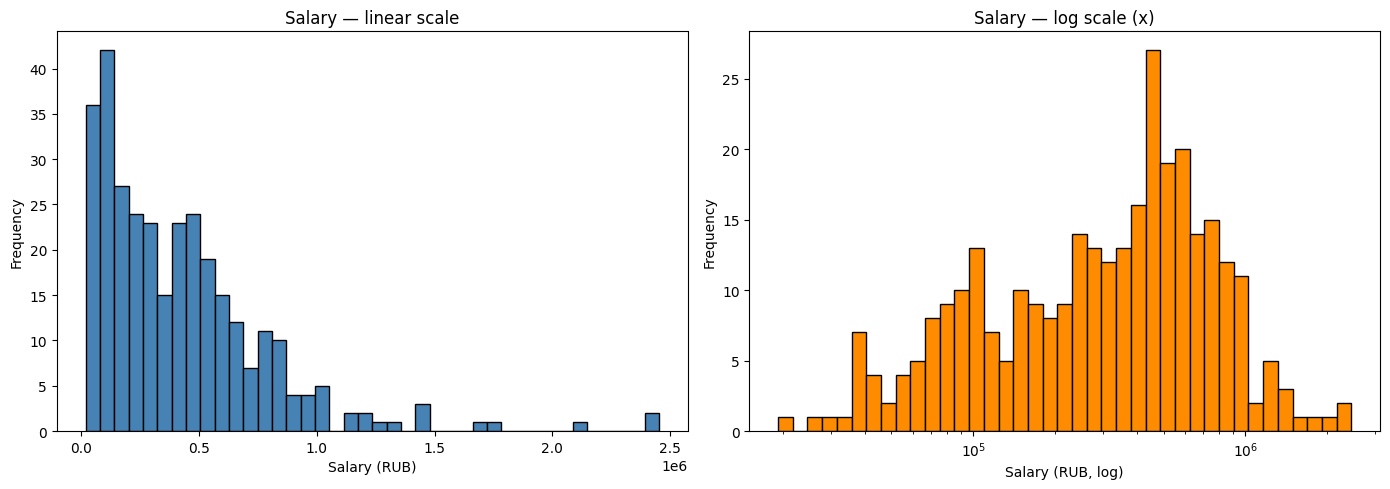

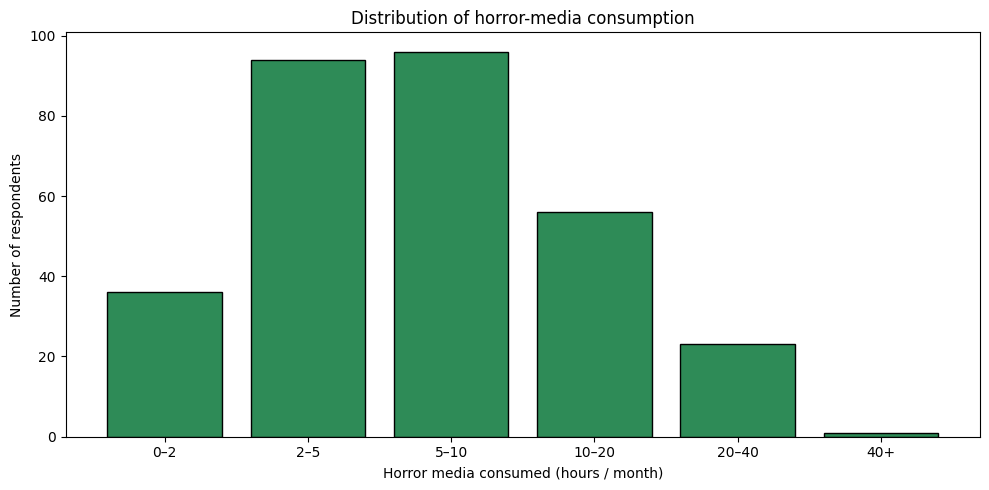

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# ---------- 1. Histogram of salaries ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) linear scale
axes[0].hist(df["salary_rub_month"].dropna(), bins=40, color="steelblue", edgecolor="black")
axes[0].set_title("Salary — linear scale")
axes[0].set_xlabel("Salary (RUB)")
axes[0].set_ylabel("Frequency")

# (b) log scale on the x-axis (compare)
bins = np.logspace(np.log10(max(df["salary_rub_month"].min(), 1)),
                   np.log10(df["salary_rub_month"].max()), 40)
axes[1].hist(df["salary_rub_month"].dropna(), bins=bins, color="darkorange", edgecolor="black")
axes[1].set_xscale("log")
axes[1].set_title("Salary — log scale (x)")
axes[1].set_xlabel("Salary (RUB, log)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


bins   = [0, 2, 5, 10, 20, 40, np.inf]
labels = ["0–2", "2–5", "5–10", "10–20", "20–40", "40+"]
hour_bins = pd.cut(df["media_horror_hours_month"], bins=bins, labels=labels)
hour_counts = hour_bins.value_counts().reindex(labels)   # keep logical order

plt.figure(figsize=(10, 5))
plt.bar(hour_counts.index, hour_counts.values,
        color="seagreen", edgecolor="black")
plt.title("Distribution of horror-media consumption")
plt.xlabel("Horror media consumed (hours / month)")
plt.ylabel("Number of respondents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ЗАДАНИЕ 02


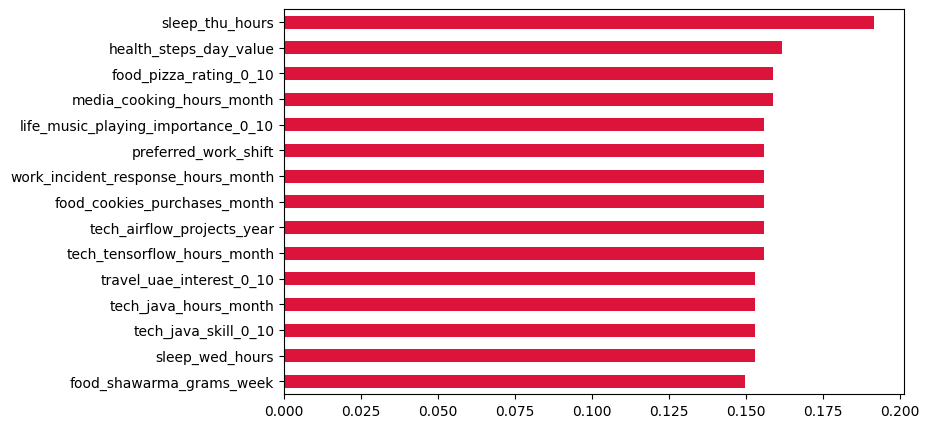

In [6]:
nan_share = df.isna().mean().sort_values(ascending=False)

top15 = nan_share.head(15)
# Or just the top-15 bar chart
top15.plot(kind="barh", figsize=(8,5), color="crimson"); plt.gca().invert_yaxis(); plt.show()

In [7]:
SENTINELS = ["?", "нет данных", "НЕИЗВЕСТНО", "-999", "-1", "999999"]

report = []
for col in df.columns:
    s = df[col].astype("string")
    for tok in SENTINELS:
        # exact match on stripped string OR numeric equality
        mask_str = s.str.strip().str.casefold() == tok.casefold()
        n_str = int(mask_str.fillna(False).sum())
        # numeric check (only for numeric-looking sentinels)
        n_num = 0
        if tok.lstrip("-").isdigit():
            n_num = int((pd.to_numeric(df[col], errors="coerce") == int(tok)).sum())
        if n_str or n_num:
            report.append((col, tok, n_str, n_num))

report = pd.DataFrame(report, columns=["column", "sentinel", "str_hits", "num_hits"])
print(report.sort_values(["column", "sentinel"]).to_string(index=False))

                                         column   sentinel  str_hits  num_hits
                                           city          ?         1         0
                            commute_minutes_day       -999         0         2
                            commute_minutes_day     999999         0         2
                   device_screen_time_hours_day         -1         0         1
                   device_screen_time_hours_day       -999         0         1
                                education_level          ?         2         0
                                education_level НЕИЗВЕСТНО         1         0
                           favorite_movie_genre НЕИЗВЕСТНО         3         0
                           favorite_movie_genre нет данных         2         0
                        food_cereal_rating_0_10          ?         6         0
                     food_ice_cream_rating_0_10          ?         4         0
                         food_sushi_rating_0_10     

In [8]:
df['exp_bin'] = pd.cut(
    df['years_in_it'],
    bins=[-np.inf, 0, 1, 3, 5, 10, np.inf],
    labels=['0', '1', '2–3', '4–5', '6–10', '>10'],
    right=True
)

miss_by_exp = (
    df.assign(salary_missing=df['salary_rub_month'].isna())
      .groupby('exp_bin', observed=True)['salary_missing']
      .agg(n_total='size', n_missing='sum', miss_rate='mean')
      .reset_index()
)


miss_by_exp['miss_rate_pct'] = (miss_by_exp['miss_rate'] * 100).round(1)

print(
    miss_by_exp[['exp_bin', 'n_total', 'n_missing', 'miss_rate_pct']]
      .rename(columns={
          'exp_bin': 'experience (yrs)',
          'n_total': 'n',
          'n_missing': 'missing',
          'miss_rate_pct': 'missing %'
      })
      .to_string(index=False)
)

experience (yrs)   n  missing  missing %
               0  65        0        0.0
               1   6        0        0.0
             2–3  19        0        0.0
             4–5  23        0        0.0
            6–10  67        5        7.5
             >10 118       14       11.9


In [9]:
df['hours_bin'] = pd.cut(
    df['work_hours_week'],
    bins=[0, 20, 30, 40, 50, np.inf],
    labels=['≤20', '21–30', '31–40', '41–50', '>50'],
    right=True
)

miss_by_hours_bin = (
    df.assign(salary_missing=df['salary_rub_month'].isna())
      .groupby('hours_bin', observed=True)['salary_missing']
      .agg(n_total='size', n_missing='sum', miss_rate='mean')
      .reset_index()
)

miss_by_hours_bin['miss_rate_pct'] = (miss_by_hours_bin['miss_rate'] * 100).round(1)

print(
    miss_by_hours_bin[['hours_bin', 'n_total', 'n_missing', 'miss_rate_pct']]
      .rename(columns={
          'hours_bin': 'weekly hours',
          'n_total': 'n',
          'n_missing': 'missing',
          'miss_rate_pct': 'missing %'
      })
      .to_string(index=False)
)



weekly hours   n  missing  missing %
         ≤20  10        0        0.0
       21–30  32        2        6.2
       31–40  66        1        1.5
       41–50  83        6        7.2
         >50 139       10        7.2


In [10]:
from scipy.stats import mannwhitneyu



# normalise stress labels in case of casing / whitespace issues
df['stress_group'] = (
    df['stress_score_0_100']
      .astype('string')
      .str.strip()
      .str.lower()
)

# --- 1. descriptive stats by group ---
stats = (
    df.groupby('stress_group')['job_satisfaction_0_10']
      .agg(n='size', mean='mean', median='median',
           std='std', q25=lambda s: s.quantile(.25),
           q75=lambda s: s.quantile(.75))
      .round(2)
)
print('\n=== job_satisfaction_0_10 by stress group ===')
print(stats)

# --- 2. Mann-Whitney U test ---
low  = df.loc[df['stress_group'] == 'low',  'job_satisfaction_0_10'].dropna()
high = df.loc[df['stress_group'] == 'high', 'job_satisfaction_0_10'].dropna()

print(f'\nn_low = {len(low)}, n_high = {len(high)}')

if len(low) and len(high):
    u, p = mannwhitneyu(low, high, alternative='two-sided')
    # rank-biserial correlation as an effect size
    rbc = 1 - (2 * u) / (len(low) * len(high))
    print(f'Mann-Whitney U = {u:.1f}, p = {p:.3g}, rank-biserial r = {rbc:+.3f}')
else:
    print('One of the groups is empty — check the stress labels.')


=== job_satisfaction_0_10 by stress group ===
              n  mean  median   std   q25   q75
stress_group                                   
11            1   8.0     8.0   NaN  8.00  8.00
13            1   6.0     6.0   NaN  6.00  6.00
14            2   4.5     4.5  0.71  4.25  4.75
15            1   8.0     8.0   NaN  8.00  8.00
16            1   6.0     6.0   NaN  6.00  6.00
...          ..   ...     ...   ...   ...   ...
72            1   4.0     4.0   NaN  4.00  4.00
73            1   NaN     NaN   NaN   NaN   NaN
8             1   6.0     6.0   NaN  6.00  6.00
81            1   6.0     6.0   NaN  6.00  6.00
9             1   NaN     NaN   NaN   NaN   NaN

[64 rows x 6 columns]

n_low = 0, n_high = 0
One of the groups is empty — check the stress labels.


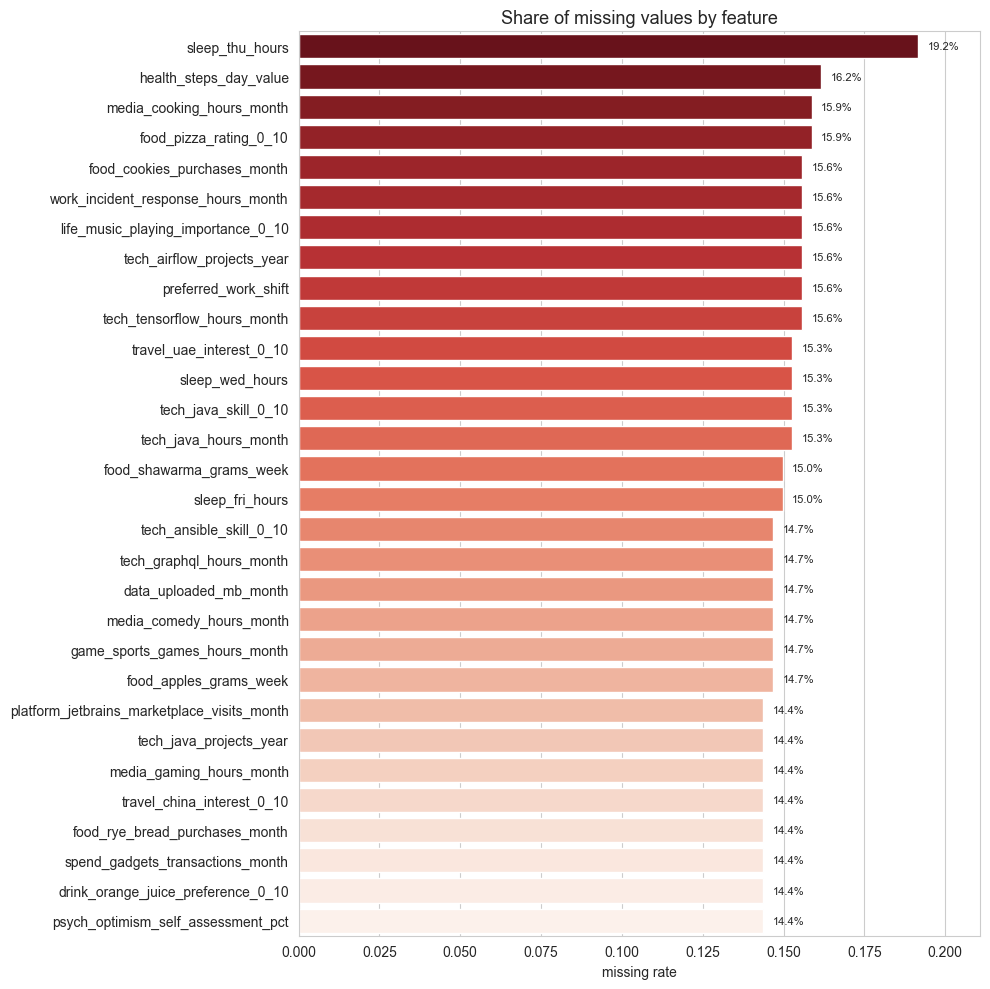

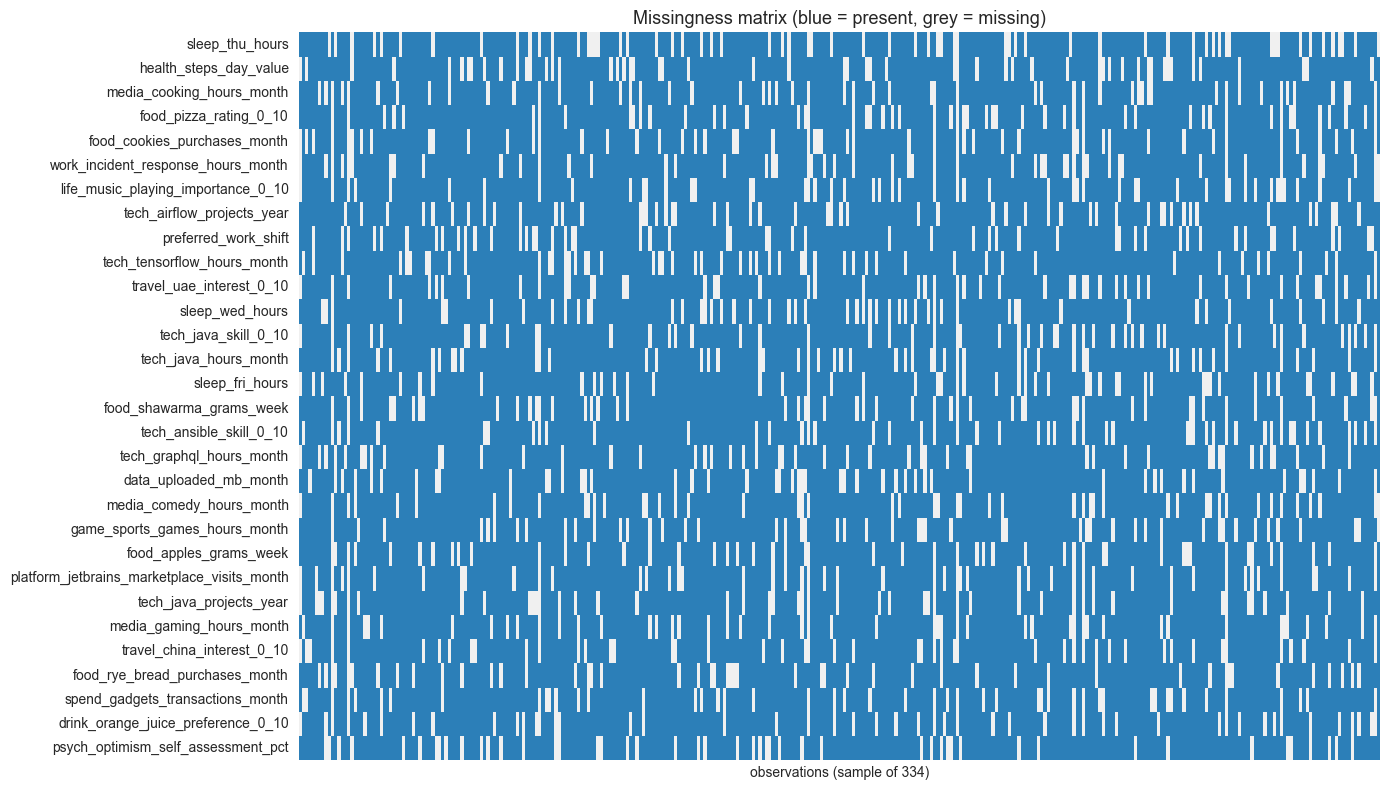

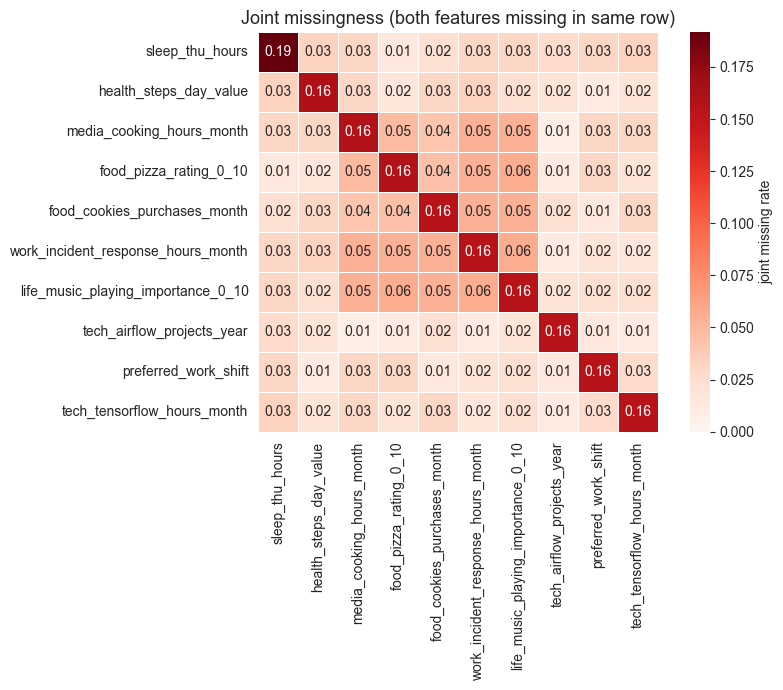

In [11]:
import seaborn as sns

sns.set_style('whitegrid')

features_30 = (
    df.isna().mean()
      .sort_values(ascending=False)
      .head(30)
      .index.tolist()
)

# keep only columns that actually exist, and require at least 10
features_30 = [c for c in features_30 if c in df.columns]
assert len(features_30) >= 10, f"only {len(features_30)} features found — need at least 10"

# =====================================================================
# 1. BAR CHART — share of missing values
# =====================================================================

miss_rate = (
    df[features_30].isna().mean()
      .sort_values(ascending=False)
      .rename('miss_rate')
      .reset_index()
      .rename(columns={'index': 'feature'})
)

fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(data=miss_rate, y='feature', x='miss_rate',
            hue='feature', legend=False, palette='Reds_r', ax=ax)
ax.set_title('Share of missing values by feature', fontsize=13)
ax.set_xlabel('missing rate')
ax.set_ylabel('')
ax.set_xlim(0, max(miss_rate['miss_rate'].max() * 1.1, 0.05))
for i, v in enumerate(miss_rate['miss_rate']):
    ax.text(v + 0.003, i, f'{v:.1%}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

# =====================================================================
# 2. MISSINGNESS MATRIX — 30 selected features
# =====================================================================

# subsample if the dataset is huge, so columns stay visible
max_rows_for_matrix = 2000
matrix_df = (
    df[features_30].sample(max_rows_for_matrix, random_state=0)
    if len(df) > max_rows_for_matrix else df[features_30]
)
missing_mask = matrix_df.isna()

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(
    missing_mask.T,               # features on rows, observations on cols
    cbar=False,
    cmap=['#2c7fb8', '#f0f0f0'],  # present = blue, missing = light grey
    yticklabels=features_30,
    xticklabels=False,
    ax=ax
)
ax.set_title('Missingness matrix (blue = present, grey = missing)', fontsize=13)
ax.set_xlabel(f'observations (sample of {len(matrix_df)})')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

# =====================================================================
# 3. JOINT MISSINGNESS HEATMAP — 10+ features
# =====================================================================

features_10 = features_30[:10]   # or provide your own 10
mask = df[features_10].isna()

joint = pd.DataFrame(
    np.zeros((len(features_10), len(features_10))),
    index=features_10, columns=features_10
)
for a in features_10:
    for b in features_10:
        joint.loc[a, b] = (mask[a] & mask[b]).mean()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    joint,
    annot=True, fmt='.2f',
    cmap='Reds',
    vmin=0, vmax=joint.values.max(),
    square=True,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'joint missing rate'},
    ax=ax
)
ax.set_title('Joint missingness (both features missing in same row)', fontsize=13)
plt.tight_layout()
plt.show()


# ЗАДАНИЕ 03

Numeric: data_uploaded_mb_month | Categorical: remote_work_mode | Sleep cols: ['sleep_mon_hours', 'sleep_tue_hours', 'sleep_wed_hours', 'sleep_thu_hours', 'sleep_fri_hours', 'sleep_sat_hours', 'sleep_sun_hours']

[data_uploaded_mb_month] NaNs: 49/334 (14.7%) | skew=11.58 | kurt=135.44
            original      mean_imp    median_imp
mean    2.876233e+07  2.876233e+07  2.455185e+07
std     2.590610e+08  2.392430e+08  2.394590e+08
median  6.232100e+04  1.480865e+05  6.232100e+04
skew    1.158300e+01  1.252900e+01  1.254800e+01


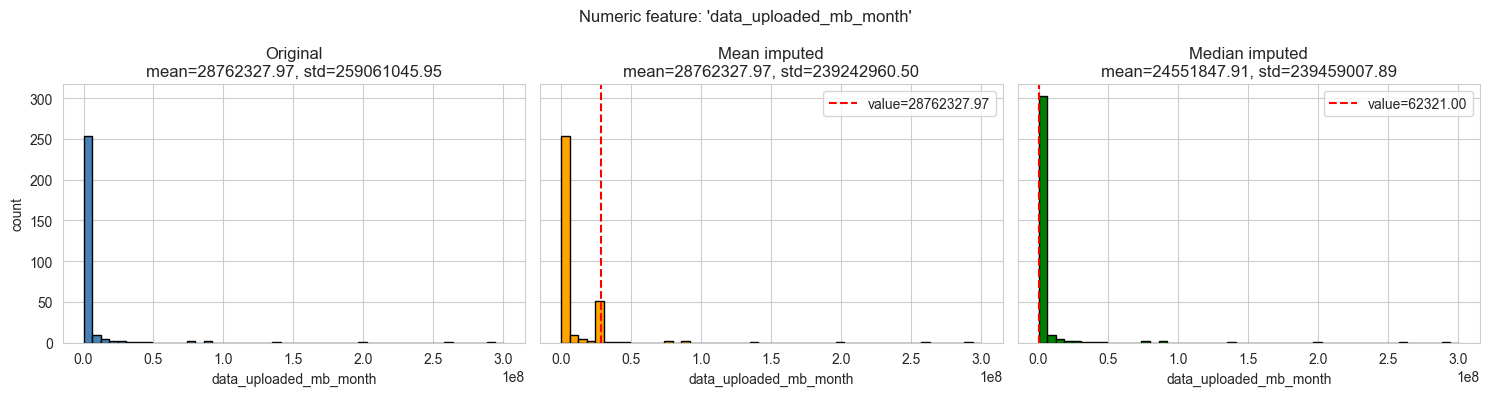


[remote_work_mode] NaNs: 30/334 (9.0%)
Top: {'гибридно': 200, 'в офисе': 61, 'удалённо': 43, nan: 30}

Category proportions:
                original  mode_imputed  not_specified
гибридно          0.658         0.689          0.599
в офисе           0.201         0.183          0.183
удалённо          0.141         0.129          0.129
not specified     0.090         0.000          0.090


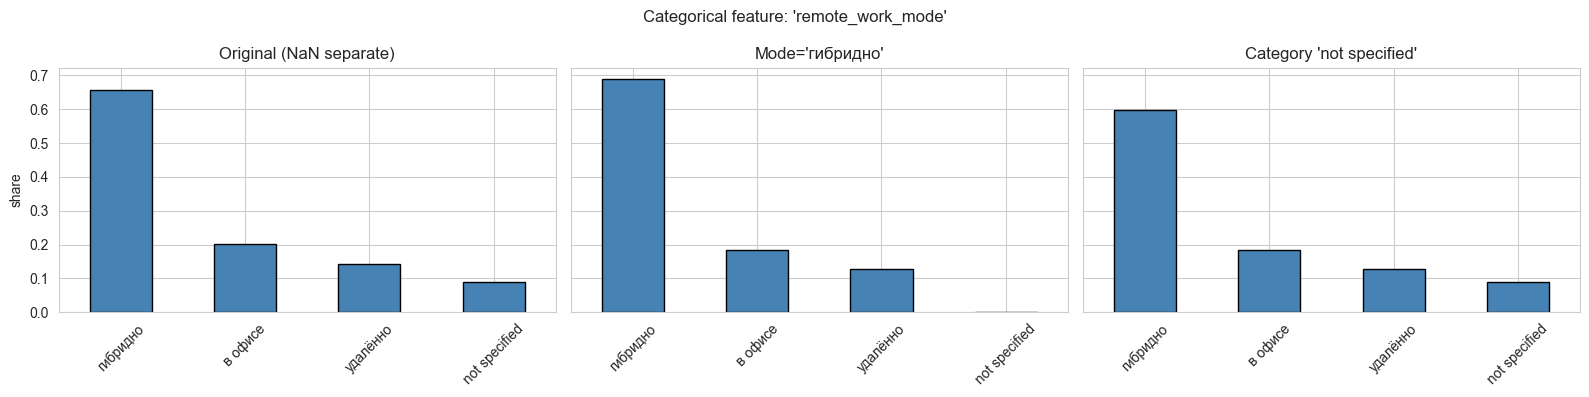


Sleep NaNs/day:
sleep_mon_hours    28
sleep_tue_hours    28
sleep_wed_hours    51
sleep_thu_hours    64
sleep_fri_hours    50
sleep_sat_hours    43
sleep_sun_hours    25
dtype: int64
Rows with ≥1 NaN: 179

Example rows:
  sleep_mon_hours  sleep_tue_hours  sleep_wed_hours  sleep_thu_hours  sleep_fri_hours  sleep_sat_hours  sleep_sun_hours
            7.90             8.43             7.59             8.07              NaN             9.64             9.10
            7.99             8.03             8.24             6.89              NaN             8.50             8.68
            8.19             7.33              NaN             7.96              NaN             7.67              NaN
            5.71             6.31              NaN             6.79             5.78              NaN             6.06
            6.39             7.30             7.32              NaN             6.75             7.14             6.45

Row 0 before:
sleep_mon_hours    7.90
sleep_tue_hours    8.43
s

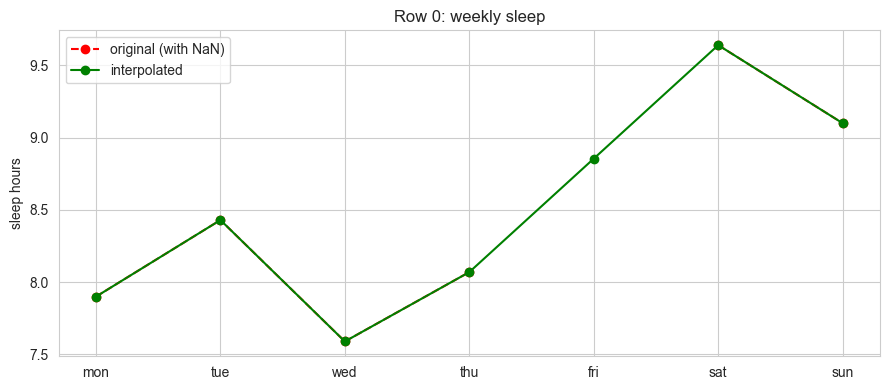

Rows total:         334
dropna() any NaN:   0 (removed 334, 100.0%)
after imputation:   334 (removed 0)

Mean comparison:
 original             2.876233e+07
mean imputation      2.876233e+07
median imputation    2.455185e+07
dtype: float64


In [12]:

NUM_COL = "data_uploaded_mb_month"
CAT_COL = "remote_work_mode"
SLEEP_COLS = [f"sleep_{d}_hours" for d in ["mon","tue","wed","thu","fri","sat","sun"]]
SLEEP_COLS = [c for c in SLEEP_COLS if c in df.columns]
print("Numeric:", NUM_COL, "| Categorical:", CAT_COL, "| Sleep cols:", SLEEP_COLS)

# ============ 1. NUMERIC: mean vs median imputation ============
num = df[NUM_COL]
print(f"\n[{NUM_COL}] NaNs: {num.isna().sum()}/{len(num)} "
      f"({num.isna().mean()*100:.1f}%) | skew={num.skew():.2f} | kurt={num.kurt():.2f}")

mean_val, median_val = num.mean(), num.median()
num_mean, num_median = num.fillna(mean_val), num.fillna(median_val)

print(pd.DataFrame({
    "original":   [num.mean(),        num.std(),        num.median(),        num.skew()],
    "mean_imp":   [num_mean.mean(),   num_mean.std(),   num_mean.median(),   num_mean.skew()],
    "median_imp": [num_median.mean(), num_median.std(), num_median.median(), num_median.skew()],
}, index=["mean","std","median","skew"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.linspace(np.nanmin(num), np.nanpercentile(num, 99), 50)
for ax, data, color, title, vline in zip(
    axes,
    [num.dropna(), num_mean, num_median],
    ["steelblue", "orange", "green"],
    [f"Original\nmean={num.mean():.2f}, std={num.std():.2f}",
     f"Mean imputed\nmean={num_mean.mean():.2f}, std={num_mean.std():.2f}",
     f"Median imputed\nmean={num_median.mean():.2f}, std={num_median.std():.2f}"],
    [None, mean_val, median_val]):
    ax.hist(data, bins=bins, color=color, edgecolor="black")
    ax.set_title(title); ax.set_xlabel(NUM_COL)
    if vline is not None:
        ax.axvline(vline, color="red", ls="--", label=f"value={vline:.2f}"); ax.legend()
axes[0].set_ylabel("count")
plt.suptitle(f"Numeric feature: '{NUM_COL}'"); plt.tight_layout(); plt.show()

# ============ 2. CATEGORICAL: mode vs "not specified" ============
cat = df[CAT_COL]
print(f"\n[{CAT_COL}] NaNs: {cat.isna().sum()}/{len(cat)} ({cat.isna().mean()*100:.1f}%)")
print("Top:", cat.value_counts(dropna=False).head(6).to_dict())

mode_val = cat.mode().iloc[0]
cat_mode, cat_unk = cat.fillna(mode_val), cat.fillna("not specified")

top = list(cat.value_counts().head(6).index) + ["not specified"]
comp = pd.DataFrame({
    "original":      [cat.isna().mean() if k == "not specified"
                      else cat.value_counts(normalize=True).get(k, 0) for k in top],
    "mode_imputed":  [cat_mode.value_counts(normalize=True).get(k, 0) for k in top],
    "not_specified": [cat_unk.value_counts(normalize=True).get(k, 0)  for k in top],
}, index=top)
print("\nCategory proportions:\n", comp.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, col, title in zip(axes, comp.columns,
    ["Original (NaN separate)", f"Mode='{mode_val}'", "Category 'not specified'"]):
    comp[col].plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
    ax.set_title(title); ax.set_ylabel("share"); ax.tick_params(axis="x", rotation=45)
plt.suptitle(f"Categorical feature: '{CAT_COL}'"); plt.tight_layout(); plt.show()

# ============ 3. WEEKLY SLEEP: interpolation ============
if SLEEP_COLS:
    sl = df[SLEEP_COLS]
    rows_nan = sl.isna().any(axis=1)
    print(f"\nSleep NaNs/day:\n{sl.isna().sum()}\nRows with ≥1 NaN: {rows_nan.sum()}")
    if rows_nan.any():
        print("\nExample rows:\n", sl[rows_nan].head().to_string(index=False))
        sl_interp = sl.interpolate(method="linear", axis=1, limit_direction="both")
        i0 = np.where(rows_nan.values)[0][0]
        print(f"\nRow {i0} before:\n{sl.iloc[i0]}\n\nRow {i0} after:\n{sl_interp.iloc[i0]}")
        fig, ax = plt.subplots(figsize=(9, 4))
        x = np.arange(len(SLEEP_COLS))
        ax.plot(x, sl.iloc[i0].values,        "o--", color="red",   label="original (with NaN)")
        ax.plot(x, sl_interp.iloc[i0].values, "o-",  color="green", label="interpolated")
        ax.set_xticks(x); ax.set_xticklabels([c[6:-6] for c in SLEEP_COLS])
        ax.set_ylabel("sleep hours"); ax.set_title(f"Row {i0}: weekly sleep"); ax.legend()
        plt.tight_layout(); plt.show()
else:
    print("\n[!] No sleep_*_hours columns")

# ============ 4. MISSING INDICATOR + ROW COUNTS ============


n, n_any, n_col = len(df), len(df.dropna()), len(df.dropna(subset=[NUM_COL]))
print(f"Rows total:         {n}")
print(f"dropna() any NaN:   {n_any} (removed {n-n_any}, {100*(n-n_any)/n:.1f}%)")
print(f"after imputation:   {n} (removed 0)")

print("\nMean comparison:\n", pd.Series({
    "original":          num.mean(),
    "mean imputation":   num_mean.mean(),
    "median imputation": num_median.mean(),
}).round(3))

# Задание_4

In [13]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer


SALARY_COL = "salary_rub_month"
AGE_COL    = "age_years"
EXP_COL    = "years_in_it"   
EXPN_COL   = "monthly_expenses_rub"



# 4–8 meaningful numeric features for Isolation Forest
NUMERIC_FEATURES = [SALARY_COL, AGE_COL, EXP_COL, EXPN_COL]

CONTAMINATION = 0.02
RANDOM_STATE  = 42
# ------------------------------------------


def iqr_flags(series: pd.Series, k: float = 1.5) -> dict:
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    mask = (series < lo) | (series > hi)          # NaN -> False automatically
    return {
        "q1": q1, "q3": q3, "iqr": iqr,
        "lower": lo, "upper": hi,
        "n_out": int(mask.sum()),
        "share": mask.mean(),                     # share of non-NaN rows
        "mask": mask,
    }

iqr_salary = iqr_flags(df[SALARY_COL])
iqr_age    = iqr_flags(df[AGE_COL])

for name, r in [("salary_rub_month", iqr_salary), ("age_years", iqr_age)]:
    print(f"\n{name}")
    print(f"  Q1={r['q1']:.2f}  Q3={r['q3']:.2f}  IQR={r['iqr']:.2f}")
    print(f"  bounds = [{r['lower']:.2f}, {r['upper']:.2f}]")
    print(f"  outliers = {r['n_out']}  ({r['share']*100:.2f}%)")





salary_rub_month
  Q1=142741.00  Q3=573583.50  IQR=430842.50
  bounds = [-503522.75, 1219847.25]
  outliers = 10  (2.99%)

age_years
  Q1=25.00  Q3=37.00  IQR=12.00
  bounds = [7.00, 55.00]
  outliers = 1  (0.30%)


In [14]:
def zscore_flags(series: pd.Series, thresh: float = 3.0) -> dict:
    s = series.dropna()
    mu, sd = s.mean(), s.std(ddof=0)
    z = (series - mu) / sd
    mask = z.abs() > thresh
    return {"mean": mu, "std": sd, "mask": mask,
            "n_out": int(mask.sum()), "share": mask.mean()}

# Pick the most symmetric numeric feature among the candidates
sym_pool = [c for c in NUMERIC_FEATURES if c in df.columns]
skew = df[sym_pool].skew().abs().sort_values()
print("|skew| per feature:\n", skew.round(3))

SYM_COL = skew.index[0]          # least-skewed feature
print(f"\nChosen symmetric feature: {SYM_COL}  (|skew|={skew.iloc[0]:.3f})")

z_sym   = zscore_flags(df[SYM_COL], thresh=3.0)
iqr_sym = iqr_flags(df[SYM_COL])

overlap = (z_sym["mask"] & iqr_sym["mask"]).sum()
print(f"\n{SYM_COL}")
print(f"  |z|>3 outliers:  {z_sym['n_out']}  ({z_sym['share']*100:.2f}%)")
print(f"  IQR outliers:    {iqr_sym['n_out']}  ({iqr_sym['share']*100:.2f}%)")
print(f"  overlap:         {overlap}")
print("  -> if |z| count >> IQR count, the tails are heavier than Gaussian; "
      "IQR is the more conservative view.")

|skew| per feature:
 years_in_it             0.552
salary_rub_month        2.026
monthly_expenses_rub    2.402
age_years               9.323
dtype: float64

Chosen symmetric feature: years_in_it  (|skew|=0.552)

years_in_it
  |z|>3 outliers:  1  (0.30%)
  IQR outliers:    1  (0.30%)
  overlap:         1
  -> if |z| count >> IQR count, the tails are heavier than Gaussian; IQR is the more conservative view.


In [15]:
X = df[NUMERIC_FEATURES].copy()

# Median imputation + missing indicators (IsolationForest cannot take NaN)
imputer = SimpleImputer(strategy="median", add_indicator=True)
X_imp = pd.DataFrame(
    imputer.fit_transform(X),
    index=df.index,
    columns=imputer.get_feature_names_out(X.columns),
)

iso = IsolationForest(
    n_estimators=300,
    contamination=CONTAMINATION,
    random_state=RANDOM_STATE,
)
iso.fit(X_imp)

df["if_score"]   = iso.decision_function(X_imp)     # higher = more normal
df["if_anomaly"] = iso.predict(X_imp) == -1

print(f"IsolationForest flags: {df['if_anomaly'].sum()} "
      f"({df['if_anomaly'].mean()*100:.2f}%)")

IsolationForest flags: 7 (2.10%)


In [16]:
def explain(idx, row, flags: dict):
    print(f"\n--- row {idx} ---")
    for col in df.columns:
        print(f"  {col:>25}: {row[col]}")
    hits = [name for name, m in flags.items() if bool(m.loc[idx])]
    print(f"  flagged by: {hits}")
    n_missing = row[NUMERIC_FEATURES].isna().sum()
    print(f"  missing numeric fields: {n_missing}/{len(NUMERIC_FEATURES)}")

# Build a per-index flag matrix
flags = {
    "IQR_salary": iqr_salary["mask"],
    "IQR_age":    iqr_age["mask"],
    "IQR_" + SYM_COL: iqr_sym["mask"],
    "IF":         df["if_anomaly"],
}

# Pick: (a) an IF-only anomaly, (b) an IQR-on-salary anomaly
if_only = df.index[(df["if_anomaly"]) & (~iqr_salary["mask"])]
iqr_sal = df.index[iqr_salary["mask"]]

sample_idx = []
if len(if_only):  sample_idx.append(if_only[0])
if len(iqr_sal):  sample_idx.append(iqr_sal[0])

for idx in sample_idx[:2]:
    explain(idx, df.loc[idx], flags)
    print("  -> judge: probable error / real rare phenomenon / insufficient data")


--- row 214 ---
                   nickname: NeonCosmosNavigator
                  age_years: 35.0
                  height_cm: 159.5
                  weight_kg: 68.7
                        bmi: 27.01
                years_in_it: 12.9
           salary_rub_month: nan
            work_hours_week: 61.9
            sleep_hours_day: 6.23
         stress_score_0_100: 55
            coffee_cups_day: 1.6
        exercise_hours_week: 2.13
           remote_work_mode: гибридно
            seniority_level: старший специалист
                   job_role: разработчик интерфейсов
                       city: Санкт-Петербург
             country_region: Азия
            education_level: магистратура
              risk_attitude: критический
  primary_programming_language: PHP
               preferred_os: macOS
   salary_satisfaction_0_10: 4
      job_satisfaction_0_10: 5.0
        mental_energy_0_100: 73
      physical_energy_0_100: 91.0
        monthly_savings_rub: 3687197.0
       monthly_expens

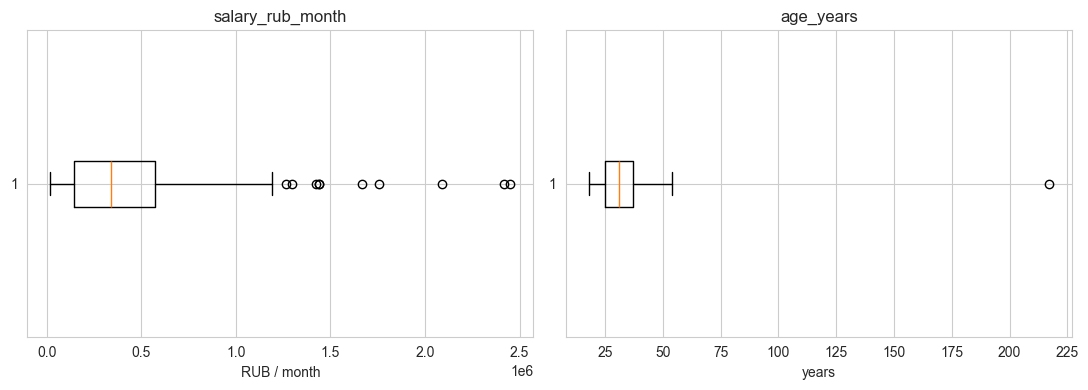

Using log axis: p99/p01 ratio ≈ 51.1, skew=2.03


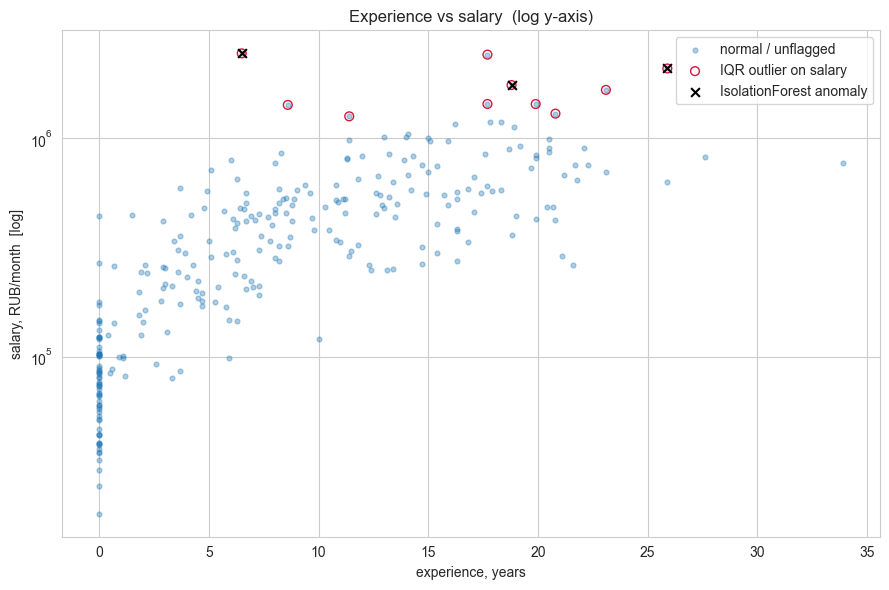

In [17]:
# --- 5a. Two boxplots ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].boxplot(df[SALARY_COL].dropna(), vert=False)
axes[0].set_title("salary_rub_month")
axes[0].set_xlabel("RUB / month")

axes[1].boxplot(df[AGE_COL].dropna(), vert=False)
axes[1].set_title("age_years")
axes[1].set_xlabel("years")

plt.tight_layout()
plt.show()

# --- 5b. Scatterplot: experience vs salary with highlighted anomalies ---
# Decide log axis by spread of positive salaries
pos = df.loc[df[SALARY_COL] > 0, SALARY_COL]
spread_ratio = pos.quantile(0.99) / pos.quantile(0.01)
use_log = (spread_ratio > 50) or (pos.skew() > 2)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df[EXP_COL], df[SALARY_COL],
           s=12, alpha=0.35, label="normal / unflagged")

# highlight IQR-salary outliers
m_sal = iqr_salary["mask"]
ax.scatter(df.loc[m_sal, EXP_COL], df.loc[m_sal, SALARY_COL],
           s=40, facecolors="none", edgecolors="crimson",
           label="IQR outlier on salary")

# highlight Isolation-Forest anomalies
m_if = df["if_anomaly"]
ax.scatter(df.loc[m_if, EXP_COL], df.loc[m_if, SALARY_COL],
           s=40, marker="x", c="black", label="IsolationForest anomaly")

if use_log:
    ax.set_yscale("log")
    ax.set_title("Experience vs salary  (log y-axis)")
    ax.set_ylabel("salary, RUB/month  [log]")
    print(f"Using log axis: p99/p01 ratio ≈ {spread_ratio:.1f}, skew={pos.skew():.2f}")
else:
    ax.set_title("Experience vs salary")
    ax.set_ylabel("salary, RUB/month")

ax.set_xlabel("experience, years")
ax.legend()
plt.tight_layout()
plt.show()

# Задание 5

In [25]:
from scipy.stats import gaussian_kde

P1, P99 = 0.01, 0.99

def make_variants(s):
    """Return three variants of a numeric series."""
    s = s.dropna()
    lo, hi = s.quantile([P1, P99])
    return {
        'original':   s,
        'winsor':     s.clip(lo, hi),
        'log1p':      np.log1p(s),
    }, lo, hi

def stats_table(variants, hi):
    rows = []
    for name, s in variants.items():
        # threshold in the same space as s
        thr = np.log1p(hi) if name == 'log1p' else hi
        rows.append({
            'strategy':   name,
            'n':          len(s),
            'mean':       s.mean(),
            'median':     s.median(),
            'variance':   s.var(),
            'skew':       s.skew(),
            'share_high': (s >= thr).mean(),      # share above original P99
            'n_above_hi': int((s >= thr).sum()),  # rare-but-valid count
        })
    return pd.DataFrame(rows)

all_rows = []
for col in ['salary_rub_month']:
    variants, lo, hi = make_variants(df[col])
    t = stats_table(variants, hi)
    t.insert(0, 'column', col)
    all_rows.append(t)
comparison = pd.concat(all_rows, ignore_index=True)
print(comparison.round(3).to_string(index=False))

          column strategy   n        mean      median            variance   skew  share_high  n_above_hi
salary_rub_month original 315 421,370.362 340,213.000 134,941,164,904.206  2.026       0.013           4
salary_rub_month   winsor 315 415,918.526 340,213.000 116,713,093,675.871  1.432       0.013           4
salary_rub_month    log1p 315      12.560      12.737               0.924 -0.429       0.013           4


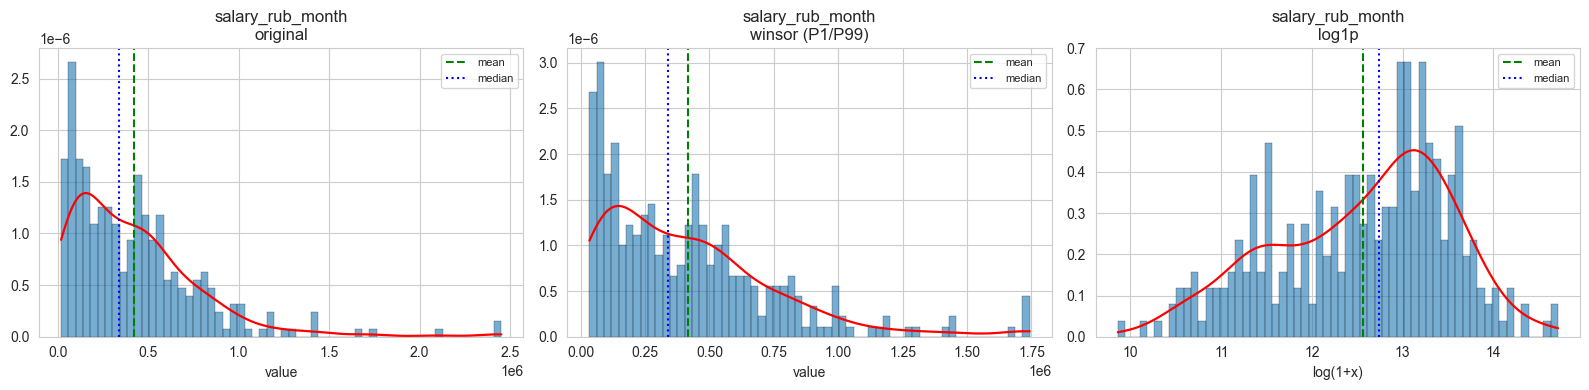

In [20]:
def plot_distributions(df, col):
    s = df[col].dropna()
    lo, hi = s.quantile([P1, P99])
    variants = {
        'original':         s,
        'winsor (P1/P99)':  s.clip(lo, hi),
        'log1p':            np.log1p(s),
    }
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (name, v) in zip(axes, variants.items()):
        ax.hist(v, bins=60, density=True, alpha=0.6, edgecolor='k', linewidth=0.3)
        try:
            kde = gaussian_kde(v, bw_method=0.3)
            xs = np.linspace(v.min(), v.max(), 300)
            ax.plot(xs, kde(xs), 'r-', lw=1.6)
        except Exception:
            pass
        ax.axvline(v.mean(),   color='green', ls='--', label='mean')
        ax.axvline(v.median(), color='blue',  ls=':',  label='median')
        ax.set_title(f'{col}\n{name}')
        ax.set_xlabel('log(1+x)' if name == 'log1p' else 'value')
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

plot_distributions(df, 'salary_rub_month')

# Задание 6

Extreme observation (original units):
salary_rub_month             7.961710e+05
sleep_hours_day              6.900000e+00
stress_score_0_100           2.800000e+01
years_in_it                  7.700000e+00
cloud_archive_bytes_total    1.528601e+15 

Per-method center / spread / extreme position:

                  feature   scaler            center_orig               spread_orig  extreme_scaled  extreme_share_%
         salary_rub_month Standard            425,715.794               366,354.051           1.013           18.255
         salary_rub_month   MinMax             19,144.000             2,432,615.000           0.319           18.255
         salary_rub_month   Robust            352,095.000               375,802.000           1.182           18.255
          sleep_hours_day Standard                  7.551                     0.789          -0.828           14.557
          sleep_hours_day   MinMax                  4.850                     4.740           0.432           14.557


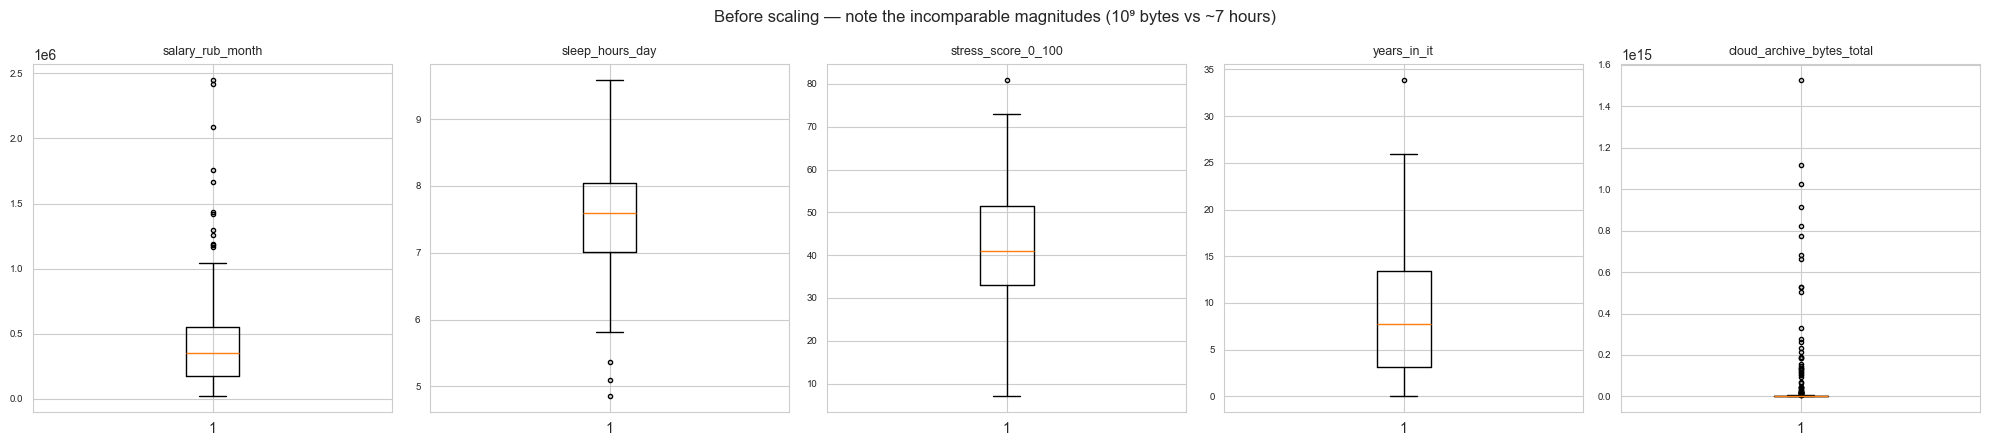

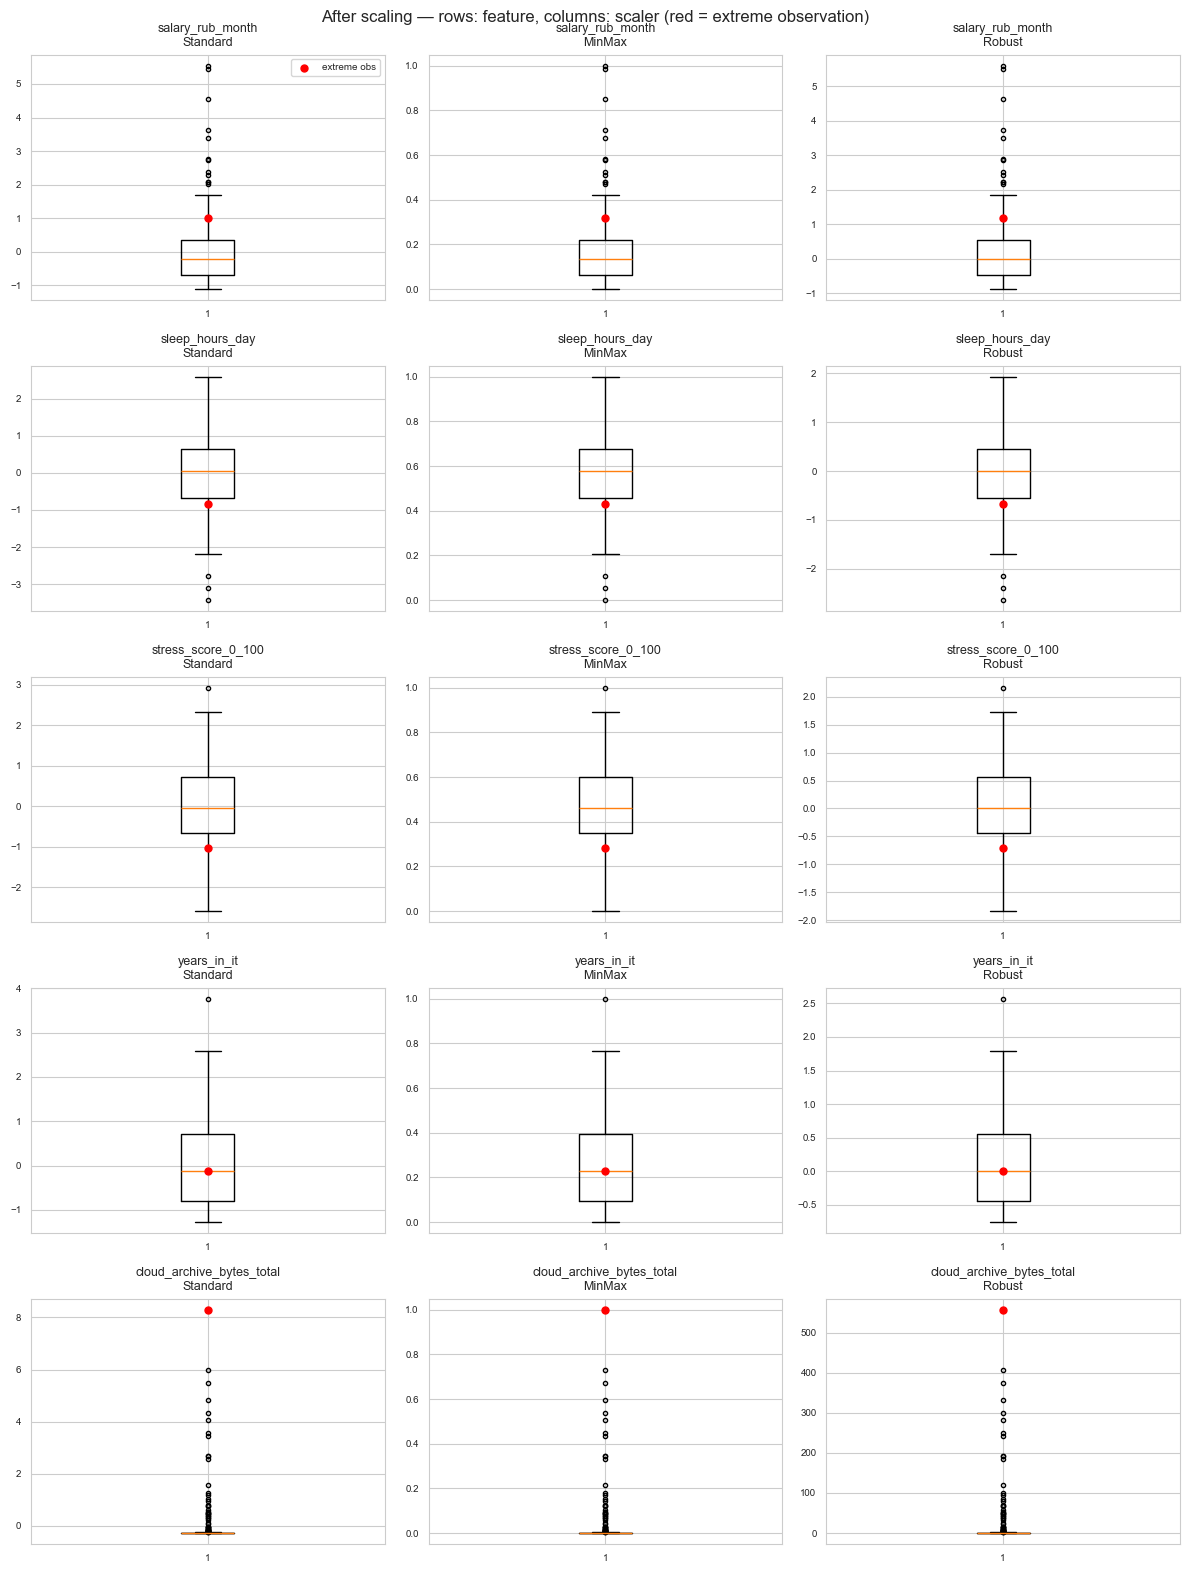

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

FEATURES = [
    "salary_rub_month",
    "sleep_hours_day",
    "stress_score_0_100",
    "years_in_it",
    "cloud_archive_bytes_total",
]
SCALER_ORDER = ["Standard", "MinMax", "Robust"]

# ------------------------------------------------------------------
# 1. Train / test split  +  imputation (fit on train only)
# ------------------------------------------------------------------
X = df[FEATURES].copy()
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)

# ------------------------------------------------------------------
# 2. Fit the three scalers on TRAIN
# ------------------------------------------------------------------
scalers = {
    "Standard": StandardScaler(),
    "MinMax":   MinMaxScaler(),
    "Robust":   RobustScaler(),
}
scaled = {
    name: pd.DataFrame(sc.fit_transform(X_train_imp), columns=FEATURES, index=X_train_imp.index)
    for name, sc in scalers.items()
}

# ------------------------------------------------------------------
# 3. Pick one EXTREME observation (max of cloud_archive_bytes_total)
# ------------------------------------------------------------------
ext_idx = X_train_imp["cloud_archive_bytes_total"].idxmax()
ext_row = X_train_imp.loc[ext_idx]
print("Extreme observation (original units):")
print(ext_row.to_string(), "\n")

# ------------------------------------------------------------------
# 4. Center / spread / extreme position per feature × scaler
# ------------------------------------------------------------------
rows = []
for col in FEATURES:
    for name in SCALER_ORDER:
        if name == "Standard":
            center = X_train_imp[col].mean()
            spread = X_train_imp[col].std()
        elif name == "MinMax":
            center = X_train_imp[col].min()
            spread = X_train_imp[col].max() - X_train_imp[col].min()
        else:  # Robust
            center = X_train_imp[col].median()
            spread = X_train_imp[col].quantile(0.75) - X_train_imp[col].quantile(0.25)

        rows.append({
            "feature":          col,
            "scaler":           name,
            "center_orig":      center,
            "spread_orig":      spread,
            "extreme_scaled":   scaled[name].loc[ext_idx, col],
            # how much of the scaled range does the extreme occupy?
            "extreme_share_%": 100 * abs(scaled[name].loc[ext_idx, col]
                                         - scaled[name][col].median())
                                / (scaled[name][col].max() - scaled[name][col].min()),
        })

stats = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Per-method center / spread / extreme position:\n")
print(stats.to_string(index=False))

# ------------------------------------------------------------------
# 5. Figure 1 — boxplots of the 5 features BEFORE scaling
#    (one subplot each: raw magnitudes differ by ~10^9, so a single
#     shared axis would be unreadable — the y-axes themselves already
#     demonstrate the scale mismatch)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, FEATURES):
    ax.boxplot(X_train_imp[col].dropna(), flierprops=dict(markersize=3))
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Before scaling — note the incomparable magnitudes (10⁹ bytes vs ~7 hours)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 6. Figure 2 — ONE comparative graph after the three methods
#    Rows = features, columns = scalers. Red dot = extreme observation.
# ------------------------------------------------------------------
fig, axes = plt.subplots(len(FEATURES), 3, figsize=(12, 16))
for i, col in enumerate(FEATURES):
    for j, name in enumerate(SCALER_ORDER):
        ax = axes[i, j]
        ax.boxplot(scaled[name][col].dropna(), flierprops=dict(markersize=3))
        ax.scatter([1], [scaled[name].loc[ext_idx, col]],
                   color="red", zorder=5, s=25, label="extreme obs")
        ax.set_title(f"{col}\n{name}", fontsize=9)
        ax.tick_params(labelsize=7)
        if i == 0 and j == 0:
            ax.legend(fontsize=7, loc="upper right")
fig.suptitle("After scaling — rows: feature, columns: scaler (red = extreme observation)")
plt.tight_layout()
plt.show()

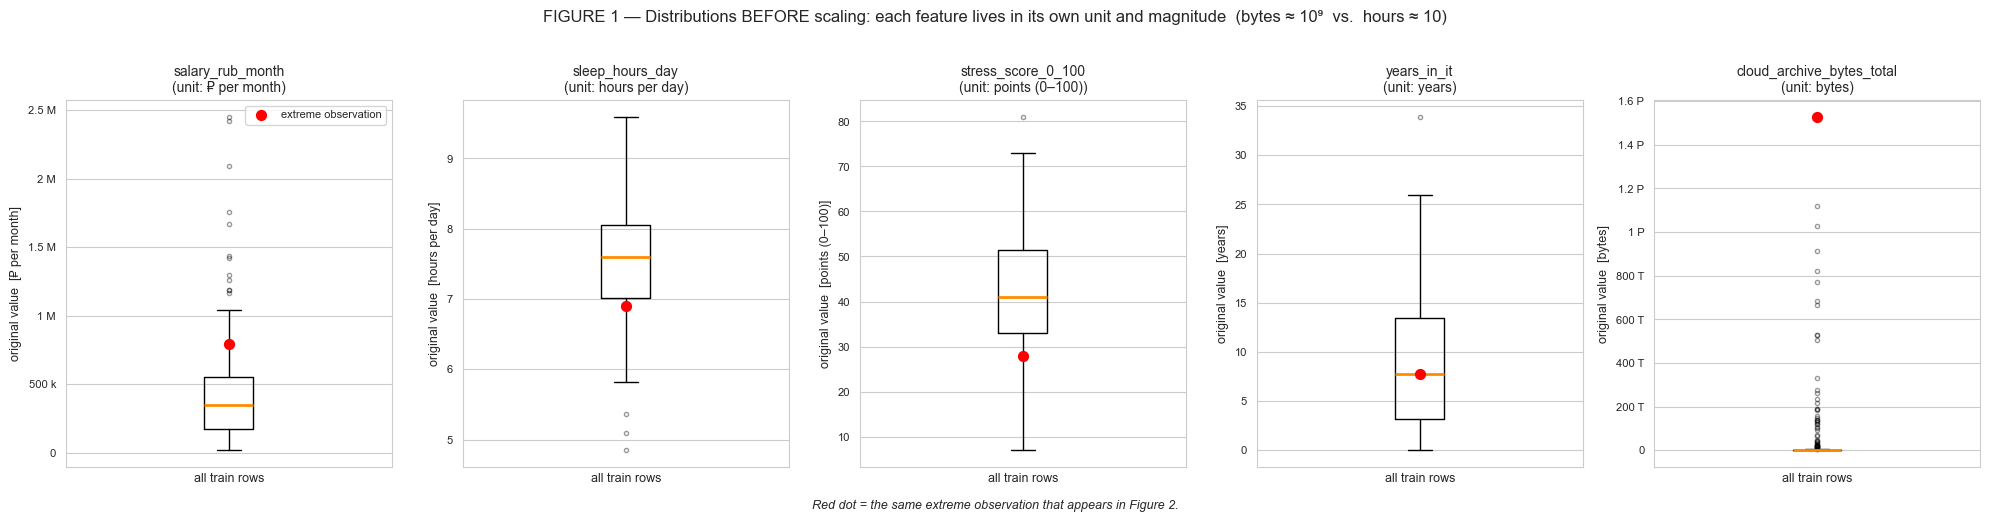

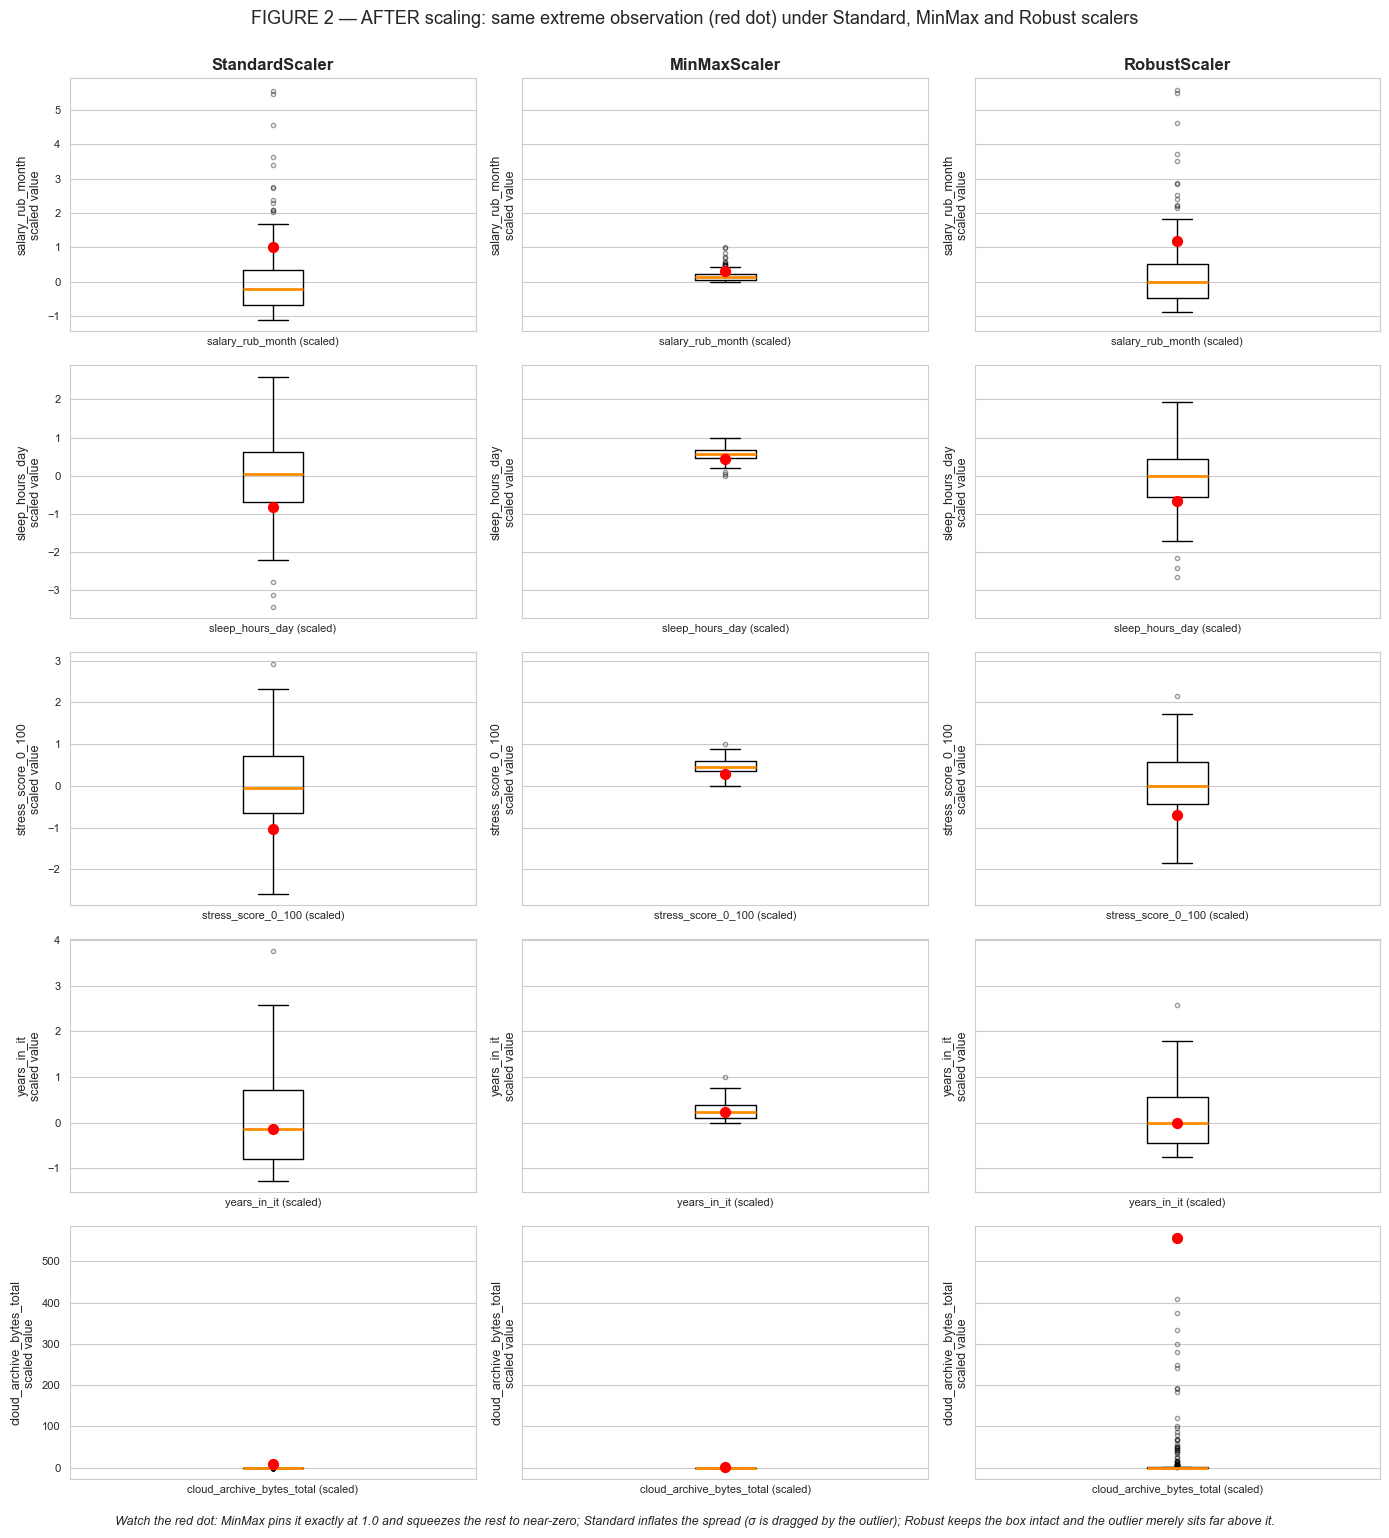

In [22]:
import matplotlib.ticker as mticker

UNITS = {
    "salary_rub_month":           "₽ per month",
    "sleep_hours_day":            "hours per day",
    "stress_score_0_100":         "points (0–100)",
    "years_in_it":                "years",
    "cloud_archive_bytes_total":  "bytes",
}

# ==================================================================
# FIGURE 1 — "The problem": raw distributions, each on its own scale
# ==================================================================
fig, axes = plt.subplots(1, 5, figsize=(20, 4.8))

for ax, col in zip(axes, FEATURES):
    ax.boxplot(
        X_train_imp[col].dropna(),
        flierprops=dict(marker="o", markersize=3, alpha=0.4),
        medianprops=dict(color="darkorange", linewidth=2),
    )
    # mark the extreme observation (same row as in Figure 2)
    ax.scatter(
        [1], [X_train_imp.loc[ext_idx, col]],
        color="red", s=50, zorder=5,
        label="extreme observation",
    )

    ax.set_title(f"{col}\n(unit: {UNITS[col]})", fontsize=10)
    ax.set_ylabel(f"original value  [{UNITS[col]}]", fontsize=9)
    ax.set_xlabel("all train rows", fontsize=9)
    ax.set_xticks([])                       # single box → x-tick meaningless
    ax.tick_params(axis="y", labelsize=8)
    ax.yaxis.set_major_formatter(mticker.EngFormatter())

axes[0].legend(loc="upper right", fontsize=8)

fig.suptitle(
    "FIGURE 1 — Distributions BEFORE scaling: "
    "each feature lives in its own unit and magnitude  "
    "(bytes ≈ 10⁹  vs.  hours ≈ 10)",
    fontsize=12, y=1.02,
)
fig.text(
    0.5, -0.02,
    "Red dot = the same extreme observation that appears in Figure 2.",
    ha="center", fontsize=9, style="italic",
)
plt.tight_layout()
plt.show()


# ==================================================================
# FIGURE 2 — "The effect": same 5 features, after each of the 3 scalers
# ==================================================================
fig, axes = plt.subplots(
    len(FEATURES), 3,
    figsize=(14, 3.0 * len(FEATURES)),
    sharey="row",
)

for i, col in enumerate(FEATURES):
    for j, name in enumerate(SCALER_ORDER):
        ax = axes[i, j]

        ax.boxplot(
            scaled[name][col].dropna(),
            flierprops=dict(marker="o", markersize=3, alpha=0.4),
            medianprops=dict(color="darkorange", linewidth=2),
        )
        # extreme observation — red dot, identical row across all panels
        ax.scatter(
            [1], [scaled[name].loc[ext_idx, col]],
            color="red", s=50, zorder=5,
        )

        # ---- titles & labels -------------------------------------
        if i == 0:
            ax.set_title(f"{name}Scaler", fontsize=12, fontweight="bold")
        ax.set_ylabel(f"{col}\nscaled value", fontsize=9)
        ax.set_xlabel(f"{col} (scaled)", fontsize=8)
        ax.set_xticks([])
        ax.tick_params(axis="y", labelsize=8)

fig.suptitle(
    "FIGURE 2 — AFTER scaling: same extreme observation (red dot) "
    "under Standard, MinMax and Robust scalers",
    fontsize=13, y=1.00,
)
fig.text(
    0.5, -0.01,
    "Watch the red dot: MinMax pins it exactly at 1.0 and squeezes "
    "the rest to near-zero; Standard inflates the spread (σ is dragged by the outlier); "
    "Robust keeps the box intact and the outlier merely sits far above it.",
    ha="center", fontsize=9, style="italic", wrap=True,
)
plt.tight_layout()
plt.show()

# Задание 7

Top candidates (orders of magnitude):
project_website_views_total       11.307
cloud_archive_bytes_total         11.126
open_source_donations_rub_year     8.922
data_uploaded_mb_month             8.502
lines_of_code_month                7.185
messages_sent_month                6.982
commute_minutes_day                5.523
internet_traffic_gb_month          5.112
monthly_savings_rub                3.238
sport_rowing_minutes_week          3.086
sport_walking_minutes_week         3.017
sport_hiking_minutes_week          3.009
sport_dancing_minutes_week         3.000
sport_yoga_minutes_week            2.933
home_ergonomic_chair_budget_rub    2.897

Chosen features: ['cloud_archive_bytes_total', 'project_website_views_total', 'open_source_donations_rub_year']
Spreads (orders of magnitude): [11.13, 11.31, 8.92]


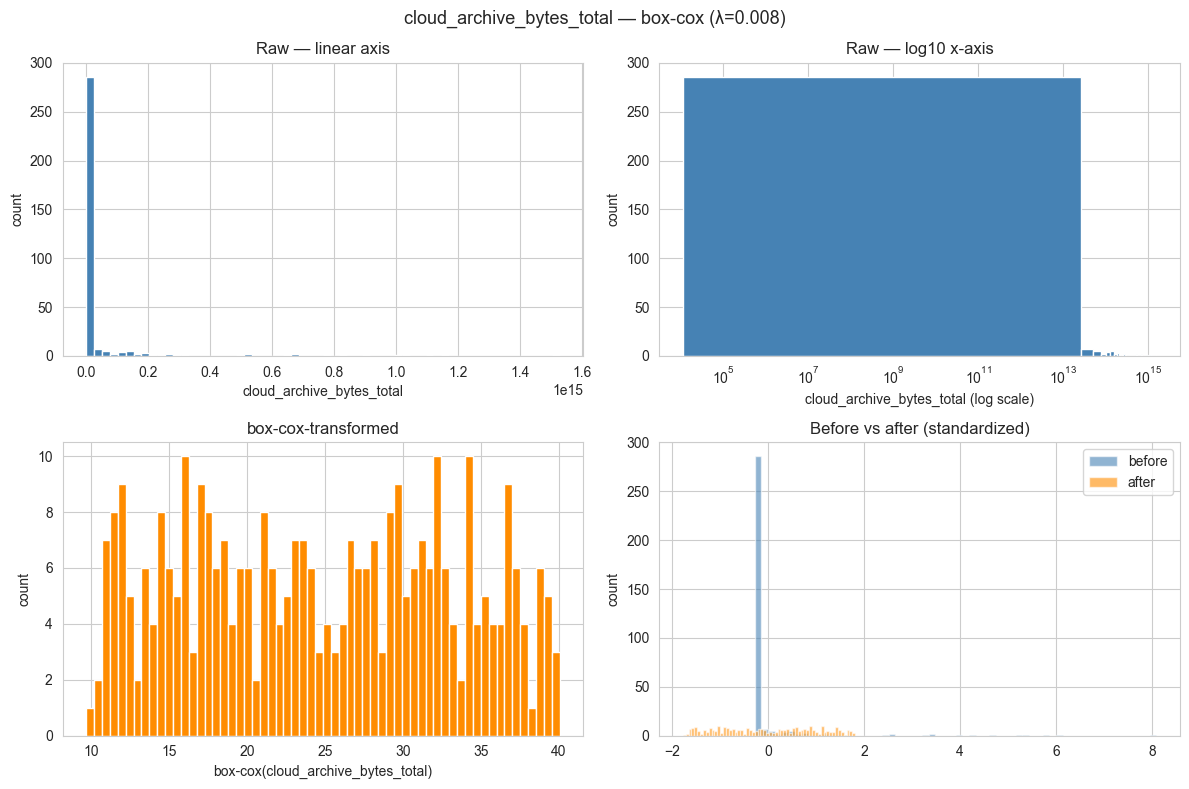

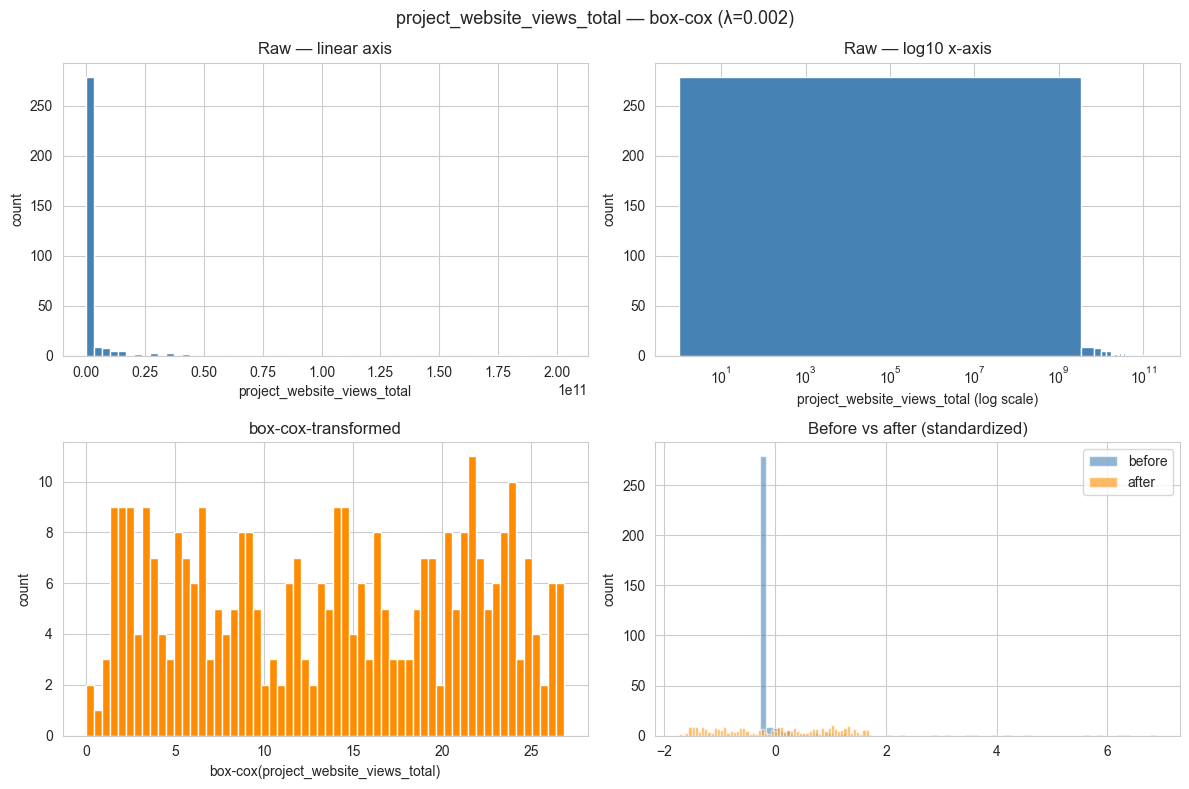

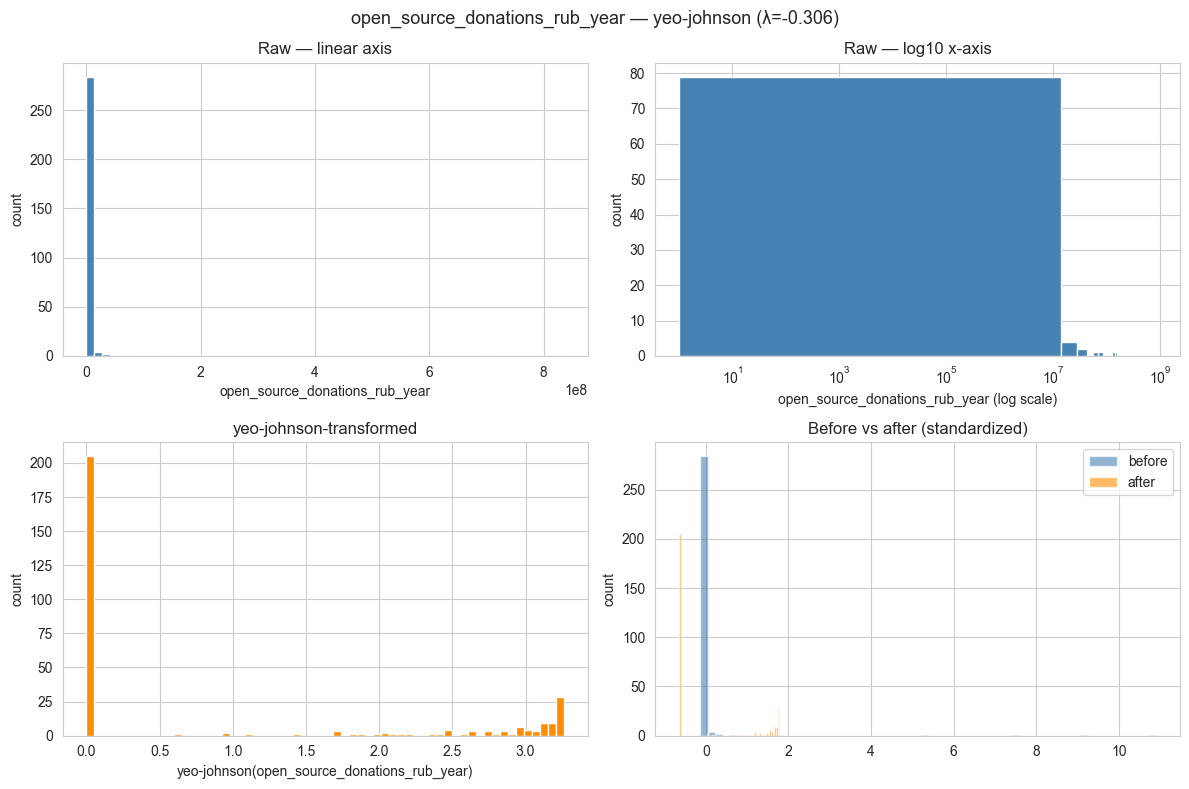

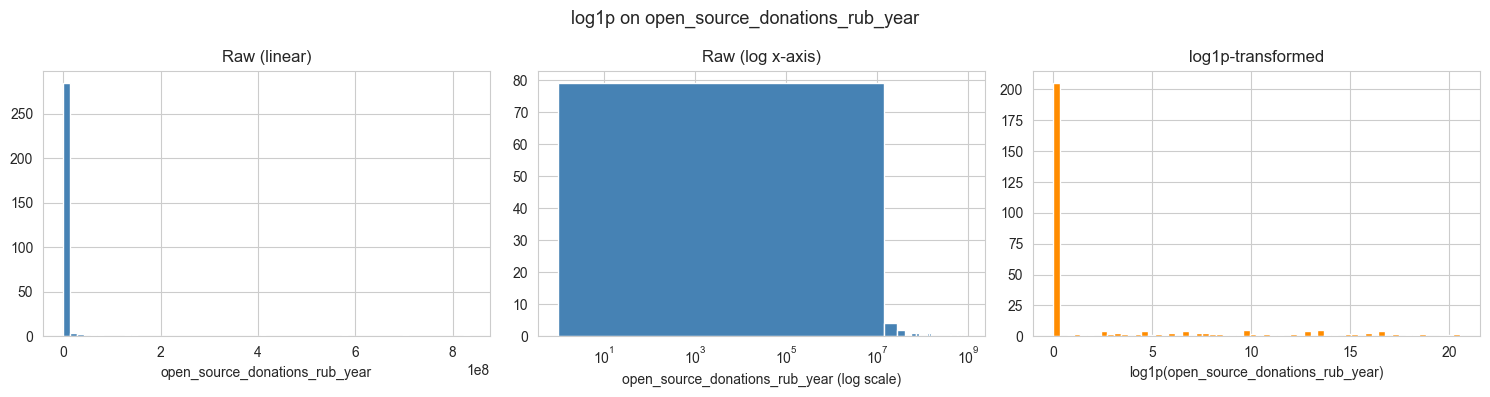


log1p demo — open_source_donations_rub_year:
  skew   8.811 -> 1.663
  median 0.000 -> 0.000


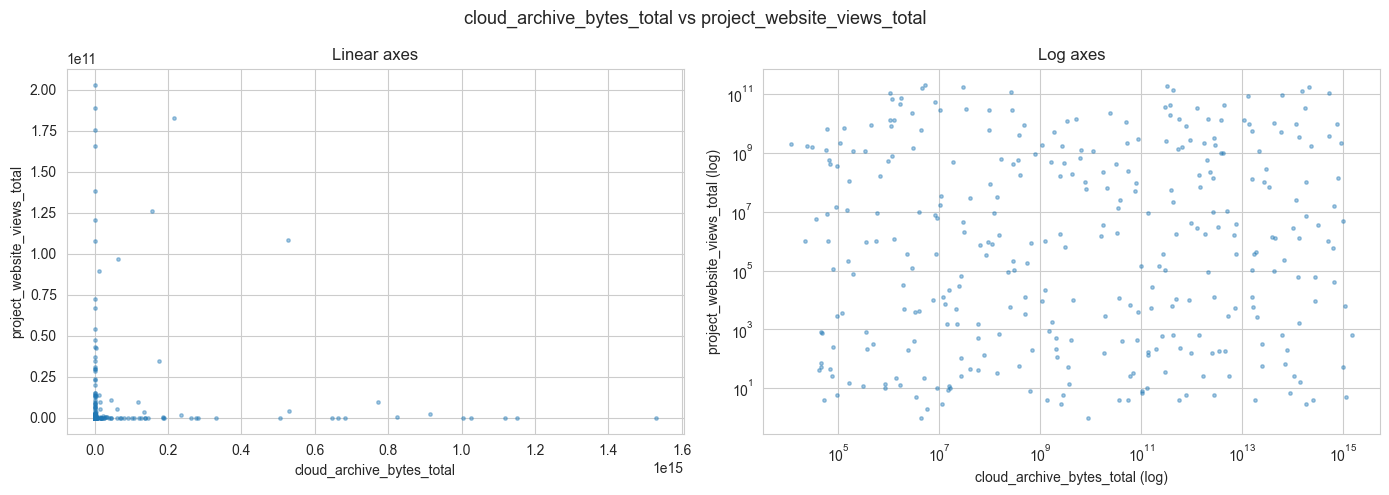


=== Summary (transforms fit on train, evaluated on full data) ===
                       feature      method  lambda  skew_before  skew_after     median_before  median_after  orders
     cloud_archive_bytes_total     box-cox   0.008        4.952       0.025 4,837,161,259.500        24.306  11.130
   project_website_views_total     box-cox   0.002        4.821      -0.027     1,004,920.000        14.036  11.310
open_source_donations_rub_year yeo-johnson  -0.306        8.811       0.960             0.000         0.000   8.920


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer
from scipy.stats import skew as _scipy_skew



# ============================================================
# 1. Find features with >= 4 orders of magnitude spread
# ============================================================
def orders_of_magnitude(s):
    s = s.dropna()
    pos = s[s > 0]
    if len(pos) < 30:
        return np.nan
    return np.log10(pos.max() / pos.min())

numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns]
spreads = (pd.Series({c: orders_of_magnitude(df[c]) for c in numeric_cols})
           .dropna().sort_values(ascending=False))

print("Top candidates (orders of magnitude):")
print(spreads.head(15).to_string())

preferred = ["cloud_archive_bytes_total",
             "project_website_views_total",
             "salary_rub_month"]
chosen = [f for f in preferred if f in spreads.index and spreads[f] >= 4]
for f in spreads.index:
    if len(chosen) >= 3:
        break
    if f not in chosen and spreads[f] >= 4:
        chosen.append(f)
chosen = chosen[:3]

if len(chosen) < 3:
    print("WARNING: <3 features reach 4 orders of magnitude — relaxing threshold.")
    chosen = list(spreads.index[:3])

print("\nChosen features:", chosen)
print("Spreads (orders of magnitude):", [round(spreads[c], 2) for c in chosen])

# ============================================================
# 2. Train/test split — fit transforms on TRAIN ONLY
# ============================================================
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

def fit_pt(feat, method):
    vals = train_df[feat].dropna().values.reshape(-1, 1)
    if method == "box-cox" and (vals <= 0).any():
        raise ValueError(f"{feat}: Box-Cox requires strictly positive values")
    pt = PowerTransformer(method=method, standardize=False)
    pt.fit(vals)
    return pt

def apply_pt(pt, series):
    out = series.astype(float).copy()
    mask = out.notna()
    out.loc[mask] = pt.transform(out[mask].values.reshape(-1, 1)).ravel()
    return out

def skew(x):
    s = pd.Series(x).dropna()
    s = s[np.isfinite(s)]
    return float(_scipy_skew(s.values)) if len(s) > 2 else np.nan

def med(x):
    return float(pd.Series(x).dropna().median())

# ============================================================
# 3. Per-feature: linear vs log10 axis + Box-Cox / Yeo-Johnson
# ============================================================
rows = []

for feat in chosen:
    s = df[feat]
    vals = s.dropna()
    strictly_pos = (vals > 0).all()
    method = "box-cox" if strictly_pos else "yeo-johnson"

    pt = fit_pt(feat, method)
    transformed = apply_pt(pt, s)

    rows.append({
        "feature": feat,
        "method": method,
        "lambda": round(float(pt.lambdas_[0]), 4),
        "skew_before":  round(skew(s), 3),
        "skew_after":   round(skew(transformed), 3),
        "median_before": med(s),
        "median_after":  med(transformed),
        "orders": round(spreads[feat], 2),
    })

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"{feat} — {method} (λ={pt.lambdas_[0]:.3f})", fontsize=13)

    axes[0, 0].hist(vals, bins=60, color="steelblue")
    axes[0, 0].set_title("Raw — linear axis")
    axes[0, 0].set_xlabel(feat); axes[0, 0].set_ylabel("count")

    pos = vals[vals > 0]
    axes[0, 1].hist(pos, bins=60, color="steelblue")
    axes[0, 1].set_xscale("log")
    axes[0, 1].set_title("Raw — log10 x-axis")
    axes[0, 1].set_xlabel(f"{feat} (log scale)"); axes[0, 1].set_ylabel("count")

    axes[1, 0].hist(transformed.dropna(), bins=60, color="darkorange")
    axes[1, 0].set_title(f"{method}-transformed")
    axes[1, 0].set_xlabel(f"{method}({feat})"); axes[1, 0].set_ylabel("count")

    raw = vals.values.astype(float)
    tr  = transformed.dropna().values
    axes[1, 1].hist((raw - raw.mean())/raw.std(), bins=60,
                    alpha=0.6, label="before", color="steelblue")
    axes[1, 1].hist((tr - tr.mean())/tr.std(), bins=60,
                    alpha=0.6, label="after",  color="darkorange")
    axes[1, 1].set_title("Before vs after (standardized)")
    axes[1, 1].legend(); axes[1, 1].set_ylabel("count")

    plt.tight_layout()
    plt.savefig(f"transform_{feat}.png", dpi=120, bbox_inches="tight")
    plt.show()

# ============================================================
# 4. log1p on a non-negative feature
# ============================================================
log1p_feat = None
for f in spreads.index:
    v = df[f].dropna()
    if (v >= 0).all() and (v == 0).any():
        log1p_feat = f; break
if log1p_feat is None:
    for f in spreads.index:
        v = df[f].dropna()
        if (v >= 0).all():
            log1p_feat = f; break

if log1p_feat:
    v     = df[log1p_feat].dropna()
    v_log = np.log1p(v)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f"log1p on {log1p_feat}", fontsize=13)
    axes[0].hist(v, bins=60, color="steelblue")
    axes[0].set_title("Raw (linear)"); axes[0].set_xlabel(log1p_feat)
    axes[1].hist(v[v > 0] if (v > 0).any() else v, bins=60, color="steelblue")
    axes[1].set_xscale("log"); axes[1].set_title("Raw (log x-axis)")
    axes[1].set_xlabel(f"{log1p_feat} (log scale)")
    axes[2].hist(v_log, bins=60, color="darkorange")
    axes[2].set_title("log1p-transformed")
    axes[2].set_xlabel(f"log1p({log1p_feat})")
    plt.tight_layout()
    plt.savefig(f"log1p_{log1p_feat}.png", dpi=120, bbox_inches="tight")
    plt.show()

    print(f"\nlog1p demo — {log1p_feat}:")
    print(f"  skew   {skew(v):.3f} -> {skew(v_log):.3f}")
    print(f"  median {med(v):.3f} -> {med(v_log):.3f}")
else:
    print("\nNo non-negative feature found for log1p demo.")

# ============================================================
# 5. Scatterplot: linear vs log axes
# ============================================================
if len(chosen) >= 2:
    f1, f2 = chosen[0], chosen[1]
    sub = df[[f1, f2]].dropna()
    sub = sub[(sub[f1] > 0) & (sub[f2] > 0)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{f1} vs {f2}", fontsize=13)
    axes[0].scatter(sub[f1], sub[f2], s=6, alpha=0.4)
    axes[0].set_xlabel(f1); axes[0].set_ylabel(f2); axes[0].set_title("Linear axes")
    axes[1].scatter(sub[f1], sub[f2], s=6, alpha=0.4)
    axes[1].set_xscale("log"); axes[1].set_yscale("log")
    axes[1].set_xlabel(f"{f1} (log)"); axes[1].set_ylabel(f"{f2} (log)")
    axes[1].set_title("Log axes")
    plt.tight_layout()
    plt.savefig("scatter_linear_vs_log.png", dpi=120, bbox_inches="tight")
    plt.show()

# ============================================================
# 6. Summary table
# ============================================================
summary = pd.DataFrame(rows)
print("\n=== Summary (transforms fit on train, evaluated on full data) ===")
print(summary.to_string(index=False))

# Задание 8

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import LogisticRegression

# Pick the ID column
id_col = "last_repo_slug"
genre_col = "favorite_movie_genre"
edu_col   = "education_level"


df_work = df[[genre_col, edu_col, id_col]].dropna().copy()

# Split first: encoders must be fit on TRAIN only
train_df, test_df = train_test_split(df_work, test_size=0.2, random_state=42)

print(f"Rows: train={len(train_df)}, test={len(test_df)}")
print(f"ID column used: {id_col}")


for c in [genre_col, edu_col, id_col]:
    print(f"{c:30s} nunique={df_work[c].nunique():>6d}  "f"cardinality_ratio={df_work[c].nunique()/len(df_work):.3f}")

Rows: train=198, test=50
ID column used: last_repo_slug
favorite_movie_genre           nunique=    11  cardinality_ratio=0.044
education_level                nunique=     7  cardinality_ratio=0.028
last_repo_slug                 nunique=   245  cardinality_ratio=0.988


In [27]:
ohe_genre = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_genre.fit(train_df[[genre_col]])

X_genre_train = ohe_genre.transform(train_df[[genre_col]])
X_genre_test  = ohe_genre.transform(test_df[[genre_col]])

print("OHE genre columns:", list(ohe_genre.get_feature_names_out()))
print("Train shape:", X_genre_train.shape)

OHE genre columns: ['favorite_movie_genre_НЕИЗВЕСТНО', 'favorite_movie_genre_аниме', 'favorite_movie_genre_боевик', 'favorite_movie_genre_документальное кино', 'favorite_movie_genre_драма', 'favorite_movie_genre_комедия', 'favorite_movie_genre_научная фантастика', 'favorite_movie_genre_нет данных', 'favorite_movie_genre_триллер', 'favorite_movie_genre_ужасы', 'favorite_movie_genre_фэнтези']
Train shape: (198, 11)


In [32]:
# Real ordered levels — '?' and 'НЕИЗВЕСТНО' deliberately excluded
edu_order = [
    "школа",
    "колледж",
    "бакалавриат",
    "магистратура",
    "аспирантура",
]

# Turn the two missing-value markers into NaN in both splits
MISSING_MARKERS = {"?", "НЕИЗВЕСТНО"}
for s in (train_df, test_df):
    s[edu_col] = s[edu_col].replace(list(MISSING_MARKERS), np.nan)

# Sanity check: only known levels or NaN remain
unexpected = set(train_df[edu_col].dropna().unique()) - set(edu_order)
if unexpected:
    raise ValueError(f"Unexpected education levels: {unexpected}")

ord_edu = OrdinalEncoder(
    categories=[edu_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-1,   # requires scikit-learn >= 1.1
)
ord_edu.fit(train_df[[edu_col]])

X_edu_train = ord_edu.transform(train_df[[edu_col]]).ravel().astype(int)
X_edu_test  = ord_edu.transform(test_df[[edu_col]]).ravel().astype(int)

print("Mapping:", dict(zip(ord_edu.categories_[0],
                          range(len(ord_edu.categories_[0])))))
print("Unknown / missing -> -1")

# Distribution check
import collections
print("\nTrain distribution:", collections.Counter(X_edu_train.tolist()))
print("Test distribution: ", collections.Counter(X_edu_test.tolist()))

Mapping: {'школа': 0, 'колледж': 1, 'бакалавриат': 2, 'магистратура': 3, 'аспирантура': 4}
Unknown / missing -> -1

Train distribution: Counter({2: 70, 1: 54, 3: 46, 0: 14, 4: 12, -1: 2})
Test distribution:  Counter({2: 17, 1: 15, 3: 13, 4: 3, 0: 2})


In [33]:
genres = train_df[genre_col].unique().tolist()

# Two different arbitrary mappings
naive_A = {g: i + 1 for i, g in enumerate(genres)}
naive_B = {g: i + 1 for i, g in enumerate(reversed(genres))}

print("Mapping A:", naive_A)
print("Mapping B (reversed):", naive_B)

# ---- Error 1: equal spacing is invented ----
# e.g. if comedy=1, drama=2, horror=3, the model sees:
#     horror - drama == drama - comedy  (both = 1)
# but genres have no numeric distance.

# ---- Error 2: results depend on the arbitrary label order ----
np.random.seed(0)
y_demo = (train_df[genre_col] == genres[0]).astype(int).values
y_demo = (y_demo + np.random.binomial(1, 0.10, len(y_demo))) % 2  # noisy version of the label

X_A = train_df[genre_col].map(naive_A).values.reshape(-1, 1)
X_B = train_df[genre_col].map(naive_B).values.reshape(-1, 1)

m_A = LogisticRegression(max_iter=1000).fit(X_A, y_demo)
m_B = LogisticRegression(max_iter=1000).fit(X_B, y_demo)

print(f"Coef with mapping A: {m_A.coef_.ravel()[0]:.4f}")
print(f"Coef with mapping B: {m_B.coef_.ravel()[0]:.4f}")
# The sign/scale flips just by relabelling -> the encoding carries no real meaning.

# ---- Error 3: interpolated values get "predictions" ----
# 1.5 means "between comedy and drama" — nonsense, but the model happily answers.
print("Prediction at code 1.5:", m_A.predict_proba([[1.5]]))

# ---- Error 4: the model is forced to be monotone in genre ----
# A linear model on naive codes implies:
#     P(y=1 | code=k) is monotone in k
# which is not a property genres have.

# Compare with One-Hot Encoding: no order, no equal spacing, no interpolation
m_ohe = LogisticRegression(max_iter=1000).fit(X_genre_train, y_demo)
print("OHE coefficients (one per genre):", m_ohe.coef_.ravel())

Mapping A: {'аниме': 1, 'триллер': 2, 'боевик': 3, 'научная фантастика': 4, 'драма': 5, 'фэнтези': 6, 'ужасы': 7, 'документальное кино': 8, 'комедия': 9, 'НЕИЗВЕСТНО': 10, 'нет данных': 11}
Mapping B (reversed): {'нет данных': 1, 'НЕИЗВЕСТНО': 2, 'комедия': 3, 'документальное кино': 4, 'ужасы': 5, 'фэнтези': 6, 'драма': 7, 'научная фантастика': 8, 'боевик': 9, 'триллер': 10, 'аниме': 11}
Coef with mapping A: -0.5021
Coef with mapping B: 0.5022
Prediction at code 1.5: [[0.48185843 0.51814157]]
OHE coefficients (one per genre): [-0.27076151  3.33516355 -0.39298846 -0.40696497 -0.02577143 -0.47690528
 -0.8466203  -0.14969486 -0.15050356 -0.57130903 -0.06948984]


In [47]:
top_k = 50
top_ids = set(train_df[id_col].value_counts().head(top_k).index)

train_id_grouped = train_df[id_col].where(train_df[id_col].isin(top_ids), "OTHER").to_frame()
test_id_grouped  = test_df[id_col].where(test_df[id_col].isin(top_ids),  "OTHER").to_frame()

ohe_id = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_id_other_train = ohe_id.fit_transform(train_id_grouped)
X_id_other_test  = ohe_id.transform(test_id_grouped)

freq_map = train_df[id_col].value_counts(normalize=True)  # relative frequency

X_id_freq_train = train_df[id_col].map(freq_map).fillna(0.0).values.reshape(-1, 1)
X_id_freq_test  = test_df[id_col].map(freq_map).fillna(0.0).values.reshape(-1, 1)


N_BUCKETS = 64
hasher = FeatureHasher(n_features=N_BUCKETS, input_type="string")

X_id_hash_train = hasher.transform([[v] for v in train_df[id_col].astype(str)]).toarray()
X_id_hash_test  = hasher.transform([[v] for v in test_df[id_col].astype(str)]).toarray()


# Synthetic target = weak real signal from genre + noise, so we can see how each ID
# encoding behaves (ID itself should carry no real signal, so all should be ~baseline).
rng = np.random.default_rng(0)
y_syn = (rng.random(len(train_df)) < 0.3).astype(int)

def score(X_tr, X_te):
    m = LogisticRegression(max_iter=1000).fit(X_tr, y_syn)
    return m.score(X_te, (rng.random(len(test_df)) < 0.3).astype(int))

results = {
    "Other grouping (top-50 + OTHER)": score(X_id_other_train, X_id_other_test),
    "Frequency encoding":              score(X_id_freq_train, X_id_freq_test),
    "Hashing (64 buckets)":            score(X_id_hash_train, X_id_hash_test),
}
print("\nTest accuracy with synthetic random target (≈0.5 = no signal):")
for k, v in results.items():
    print(f"  {k:32s} {v:.3f}")


Test accuracy with synthetic random target (≈0.5 = no signal):
  Other grouping (top-50 + OTHER)  0.740
  Frequency encoding               0.800
  Hashing (64 buckets)             0.720


In [40]:
new_genre_row = pd.DataFrame({genre_col: ["новый жанр"]})

# ---- One-Hot Encoding ----
# handle_unknown="ignore" -> all-zero row, no crash
print("OHE on unseen genre:")
print(ohe_genre.transform(new_genre_row[[genre_col]]))

# What if we had used handle_unknown="error"? It would raise:
try:
    strict = OneHotEncoder(handle_unknown="error", sparse_output=False).fit(train_df[[genre_col]])
    strict.transform(new_genre_row[[genre_col]])
except ValueError as e:
    print("\nStrict OHE raised (as expected):", e)

# ---- Ordinal Encoding ----
# Unseen education level -> -1
print("\nOrdinal on unknown education level:")
print(ord_edu.transform(pd.DataFrame({edu_col: ["unknown_level"]})))

# ---- Frequency Encoding (for the ID) ----
# Unseen ID -> 0
print("\nFrequency encoding on unseen ID:",
      pd.Series(["brand_new_repo"]).map(freq_map).fillna(0.0).values)

# ---- Hashing ----
# Unseen ID is hashed automatically into one of the 64 buckets
print("Hashing on unseen ID:", hasher.transform([["brand_new_repo"]]).toarray())

OHE on unseen genre:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Strict OHE raised (as expected): Found unknown categories ['новый жанр'] in column 0 during transform

Ordinal on unknown education level:
[[-1.]]

Frequency encoding on unseen ID: [0.]
Hashing on unseen ID: [[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]]


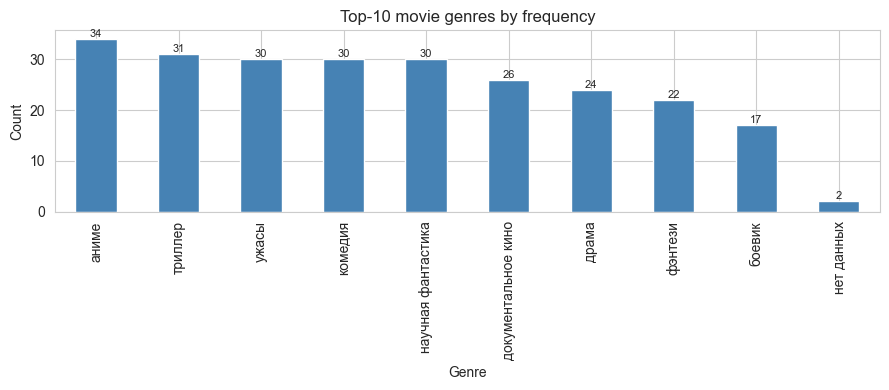

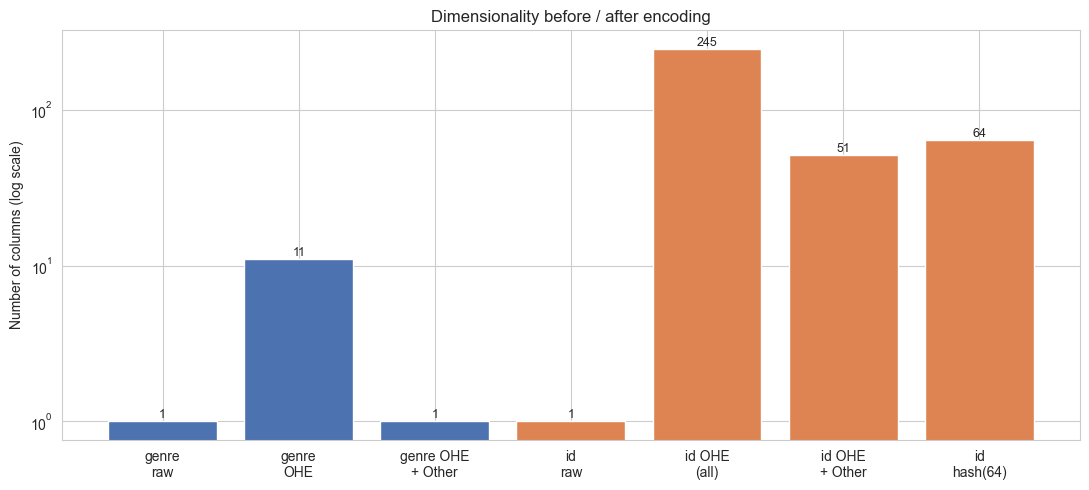

In [46]:
top10 = df_work[genre_col].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 4))
top10.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Top-10 movie genres by frequency")
ax.set_ylabel("Count")
ax.set_xlabel("Genre")
for i, v in enumerate(top10.values):
    ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

# Genre
genre_raw_cols     = 1
genre_ohe_cols     = X_genre_train.shape[1]

# Group rare genres (e.g., frequency < 50) into OTHER, then OHE
rare_threshold = 50
freq_g = train_df[genre_col].value_counts()
keep   = set(freq_g[freq_g >= rare_threshold].index)
genre_grouped = train_df[genre_col].where(train_df[genre_col].isin(keep), "OTHER").to_frame()
ohe_g_grouped = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(genre_grouped)
genre_grouped_cols = ohe_g_grouped.transform(genre_grouped).shape[1]

# ID
id_raw_cols      = 1
id_ohe_all_cols  = n_unique                 # what full OHE would produce
id_grouped_cols  = X_id_other_train.shape[1]
id_hash_cols     = N_BUCKETS

labels = ["genre\nraw", "genre\nOHE", "genre OHE\n+ Other",
          "id\nraw", "id OHE\n(all)", "id OHE\n+ Other", "id\nhash(64)"]
values = [genre_raw_cols, genre_ohe_cols, genre_grouped_cols,
          id_raw_cols, id_ohe_all_cols, id_grouped_cols, id_hash_cols]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(labels, values, color=["#4C72B0"]*3 + ["#DD8452"]*4)
ax.set_yscale("log")
ax.set_ylabel("Number of columns (log scale)")
ax.set_title("Dimensionality before / after encoding")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v}",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

# Задание 9

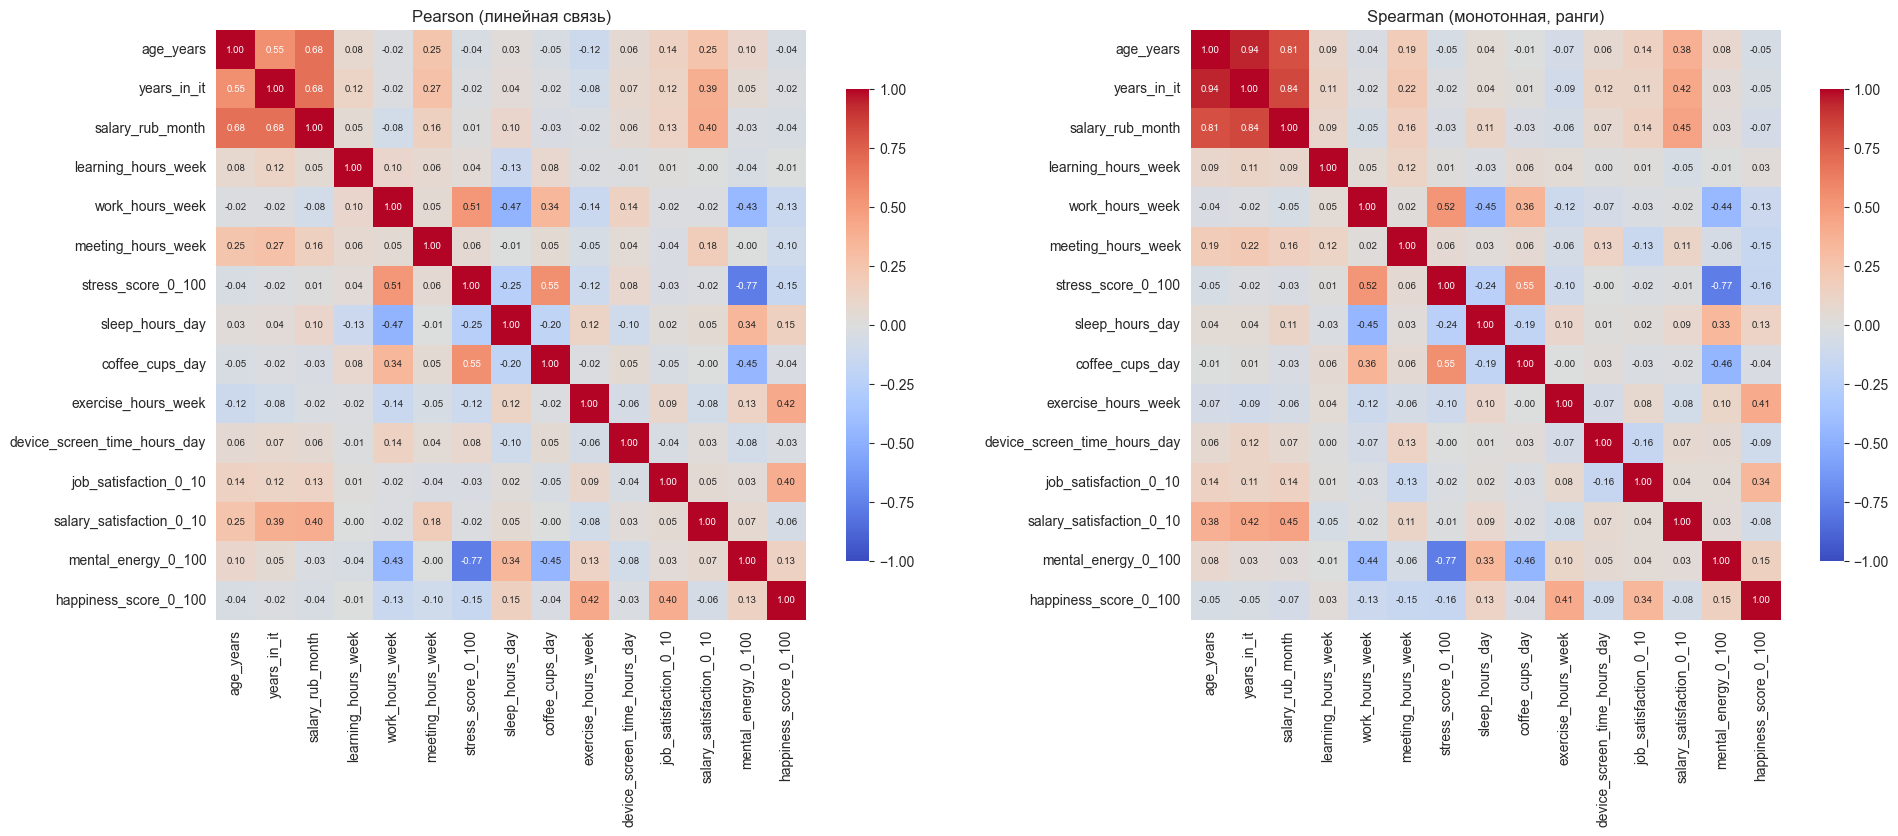

In [49]:
features = [
    'age_years', 'years_in_it', 'salary_rub_month', 'learning_hours_week',
    'work_hours_week', 'meeting_hours_week',
    'stress_score_0_100', 'sleep_hours_day', 'coffee_cups_day',
    'exercise_hours_week', 'device_screen_time_hours_day',
    'job_satisfaction_0_10', 'salary_satisfaction_0_10',
    'mental_energy_0_100', 'happiness_score_0_100',
]

X = df[features].copy()

pearson  = X.corr(method='pearson')
spearman = X.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, corr, title in zip(
    axes, [pearson, spearman],
    ['Pearson (линейная связь)', 'Spearman (монотонная, ранги)']
):
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
                vmin=-1, vmax=1, square=True, ax=ax,
                cbar_kws={'shrink': .8}, annot_kws={'size': 7})
    ax.set_title(title)
plt.tight_layout(); plt.show()

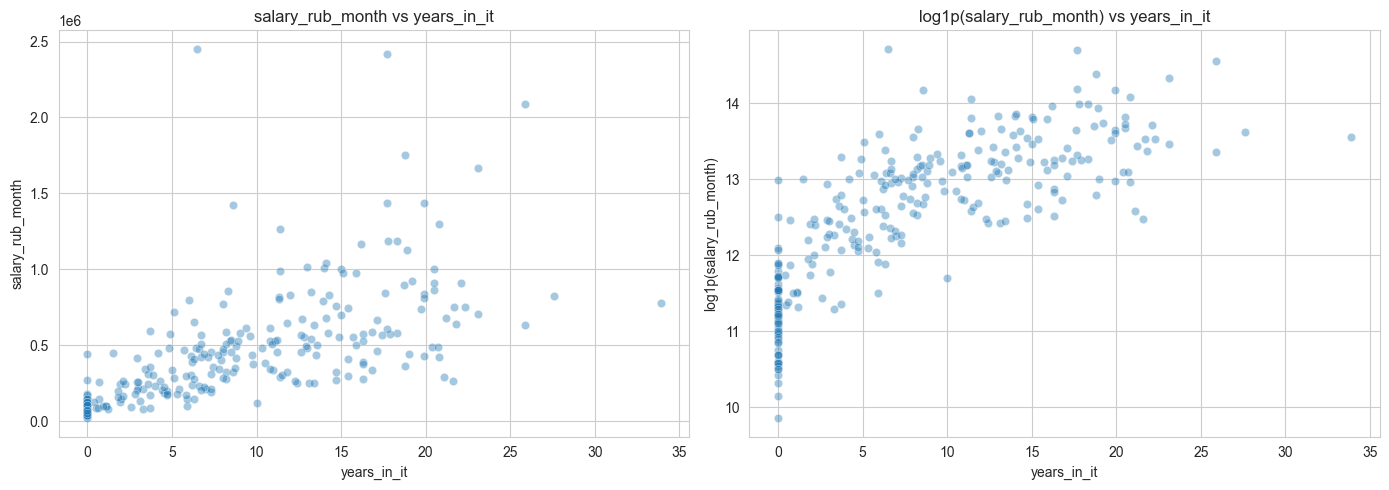

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=X, x='years_in_it', y='salary_rub_month', alpha=.4, ax=axes[0])
axes[0].set_title('salary_rub_month vs years_in_it')
axes[0].set_ylabel('salary_rub_month')

X['salary_log'] = np.log1p(X['salary_rub_month'])
sns.scatterplot(data=X, x='years_in_it', y='salary_log', alpha=.4, ax=axes[1])
axes[1].set_title('log1p(salary_rub_month) vs years_in_it')
axes[1].set_ylabel('log1p(salary_rub_month)')
plt.tight_layout(); plt.show()


--- threshold: train-75pct = 51.0 ---
sleep_hours_day            coffee_cups_day           
           mean  std count            mean  std count
           7.66 0.75   252            2.01 1.02   252
           7.23 0.81    82            2.98 1.07    82
  sleep_hours_day: mean(high)=7.23, mean(low)=7.66, t=-4.25, p=0.000
  coffee_cups_day: mean(high)=2.98, mean(low)=2.01, t=7.24, p=0.000

--- threshold: domain=60 = 60.0 ---
sleep_hours_day            coffee_cups_day           
           mean  std count            mean  std count
           7.58 0.78   313            2.17 1.08   313
           7.17 0.82    21            3.41 0.89    21
  sleep_hours_day: mean(high)=7.17, mean(low)=7.58, t=-2.20, p=0.039
  coffee_cups_day: mean(high)=3.41, mean(low)=2.17, t=6.08, p=0.000


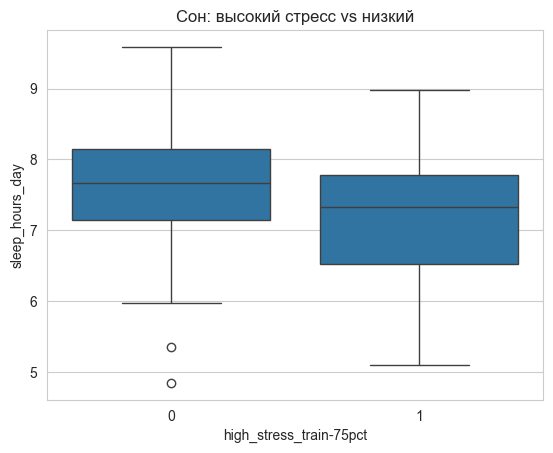

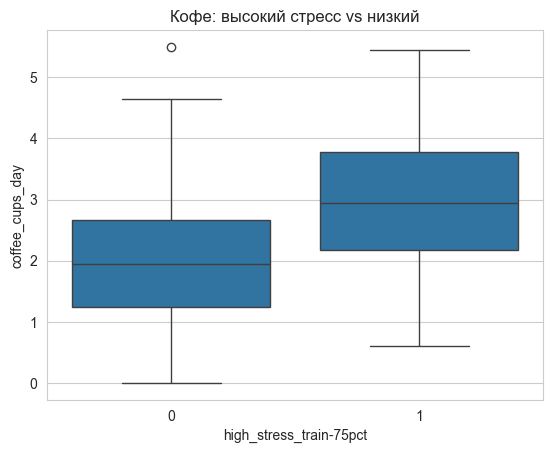

In [58]:
from scipy import stats as st  

# split чтобы не подглядывать в тест
train_idx, test_idx = train_test_split(X.index, test_size=0.3, random_state=42)

# «обученный» порог — 75-й процентиль стресса на TRAIN
thr_train = X.loc[train_idx, 'stress_score_0_100'].quantile(0.75)
# предметный порог для сравнения
thr_domain = 60

for name, thr in [('train-75pct', thr_train), ('domain=60', thr_domain)]:
    X[f'high_stress_{name}'] = (X['stress_score_0_100'] > thr).astype(int)
    print(f'\n--- threshold: {name} = {thr:.1f} ---')
    grp = X.groupby(f'high_stress_{name}')[['sleep_hours_day','coffee_cups_day']].agg(['mean','std','count'])
    print(grp.to_string(index=False, float_format='%.2f'))

    for col in ['sleep_hours_day','coffee_cups_day']:
        a = X.loc[X[f'high_stress_{name}']==1, col]
        b = X.loc[X[f'high_stress_{name}']==0, col]
        t, p = st.ttest_ind(a, b, equal_var=False, nan_policy='omit')
        print(f'  {col}: mean(high)={a.mean():.2f}, mean(low)={b.mean():.2f}, t={t:.2f}, p={p:.3f}')

# визуально
sns.boxplot(data=X, x='high_stress_train-75pct', y='sleep_hours_day')
plt.title('Сон: высокий стресс vs низкий'); plt.show()
sns.boxplot(data=X, x='high_stress_train-75pct', y='coffee_cups_day')
plt.title('Кофе: высокий стресс vs низкий'); plt.show()

In [61]:
corr = spearman.copy()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
pairs = (corr.where(mask).stack()
             .reset_index()
             .rename(columns={'level_0':'a','level_1':'b',0:'rho'}))
pairs['abs'] = pairs['rho'].abs()
pairs = pairs.sort_values('abs', ascending=False)

print('TOP-10 сильных (по |Spearman|):'); print(pairs.head(3).to_string(index=False))
print("\n")
print('\nСлабые, (|rho| < 0.1):')
print(pairs[pairs['abs'] < 0.1].head(3).to_string(index=False))

TOP-10 сильных (по |Spearman|):
          a                b   rho   abs
  age_years      years_in_it 0.940 0.940
years_in_it salary_rub_month 0.837 0.837
  age_years salary_rub_month 0.807 0.807



Слабые, (|rho| < 0.1):
                           a                     b    rho   abs
             sleep_hours_day   exercise_hours_week  0.100 0.100
device_screen_time_hours_day happiness_score_0_100 -0.094 0.094
                   age_years   learning_hours_week  0.088 0.088


# Задание 10

Numeric features : 974
Categorical features: 31
Class balance: {0: 0.8952095808383234, 1: 0.10479041916167664}
Train size: 267 | Test size: 67

=== Metrics on test set ===
                                accuracy  precision  recall    f1
model                                                            
Baseline (all 0)                   0.896      0.000   0.000 0.000
StdScaler + OHE                    0.866      0.000   0.000 0.000
RobustScaler + OHE                 0.896      0.500   0.143 0.222
Frequency enc                      0.851      0.000   0.000 0.000
OOF target enc                     0.821      0.143   0.143 0.143
LEAKY target enc (uses y_test)     0.821      0.143   0.143 0.143


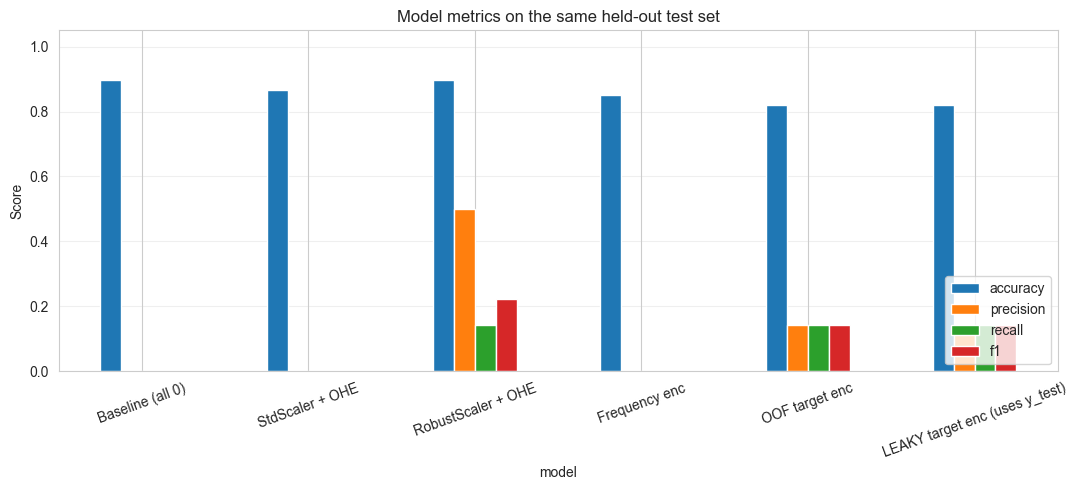

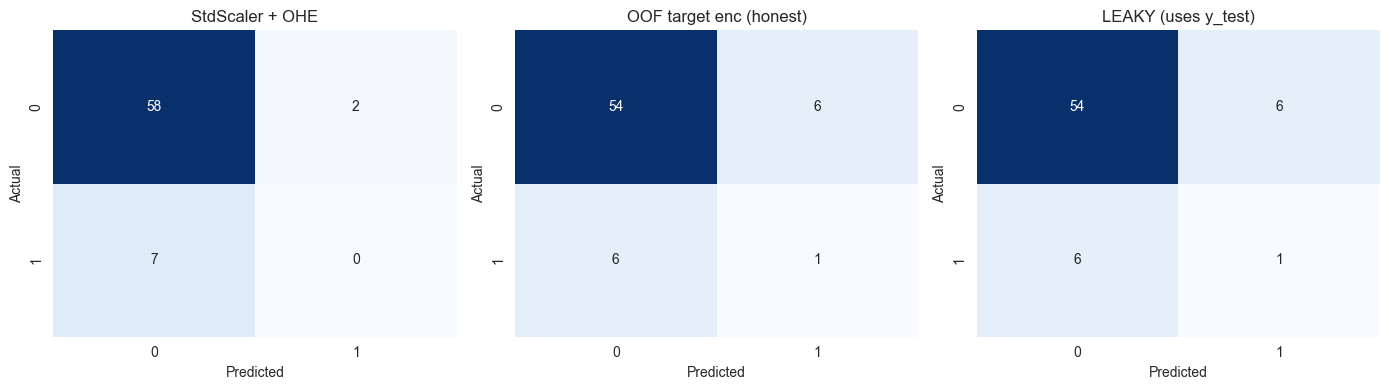


Threshold tuned on train (F1): 0.14
Tuned-threshold metrics on test:
{'accuracy': 0.821, 'precision': 0.143, 'recall': 0.143, 'f1': 0.143}


In [73]:
# =========================================================
# 0. Imports and config
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning
import warnings

# Silence only the convergence spam — liblinear shouldn't trigger it,
# but this keeps notebooks clean if a future solver changes.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
TARGET = "burnout_next_6m"
np.random.seed(RANDOM_STATE)


def make_clf():
    """liblinear: coordinate descent → no line search → no ‘f and g’ warnings.
    Still supports predict_proba() for binary targets (used by tune_threshold_cv)."""
    return LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE,
    )


# =========================================================
# 1. Split features / target
# =========================================================
assert TARGET in df.columns, f"Column {TARGET!r} not found in df"
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int).values

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numeric features : {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")
print("Class balance:", pd.Series(y).value_counts(normalize=True).to_dict())

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", len(X_tr), "| Test size:", len(X_te))


# =========================================================
# 2. Helper: metric evaluation
# =========================================================
def eval_model(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
    }


results = []
results.append(eval_model("Baseline (all 0)", y_te, np.zeros_like(y_te)))


# =========================================================
# 3. Honest variant A: StandardScaler + One-Hot
# =========================================================
pre_std = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh",  OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
pipe_std = Pipeline([("pre", pre_std), ("clf", make_clf())])   # ← make_clf
pipe_std.fit(X_tr, y_tr)
results.append(eval_model("StdScaler + OHE", y_te, pipe_std.predict(X_te)))


# =========================================================
# 4. Honest variant B: RobustScaler + One-Hot
# =========================================================
pre_rob = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  RobustScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh",  OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
pipe_rob = Pipeline([("pre", pre_rob), ("clf", make_clf())])   # ← make_clf
pipe_rob.fit(X_tr, y_tr)
results.append(eval_model("RobustScaler + OHE", y_te, pipe_rob.predict(X_te)))


# =========================================================
# 5. Custom transformers: frequency + target encoding
# =========================================================
class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each category with its frequency computed on the fit set."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.maps_ = {
            c: X[c].astype(object).value_counts(normalize=True).to_dict()
            for c in X.columns
        }
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        cols = [
            X[c].astype(object).map(self.maps_[c])
                 .fillna(0.0).astype(float).values
            for c in X.columns
        ]
        return np.column_stack(cols).astype(float)


class TargetEncoder(BaseEstimator, TransformerMixin):
    """Smoothed target encoding. Fit must receive (X, y)."""
    def __init__(self, smoothing=10):
        self.smoothing = smoothing

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(np.asarray(y)).reset_index(drop=True)
        self.global_mean_ = float(y.mean())
        self.maps_ = {}
        for c in X.columns:
            col = X[c].astype(object)
            stats = y.groupby(col).agg(["mean", "count"])
            sm = (stats["mean"] * stats["count"]
                  + self.global_mean_ * self.smoothing) \
                 / (stats["count"] + self.smoothing)
            self.maps_[c] = sm.to_dict()
        return self

    def transform(self, X):
        X = pd.DataFrame(X).reset_index(drop=True)
        cols = [
            X[c].astype(object).map(self.maps_[c])
                 .fillna(self.global_mean_).astype(float).values
            for c in X.columns
        ]
        return np.column_stack(cols).astype(float)


# =========================================================
# 6. Honest variant C: Frequency encoding for categoricals
# =========================================================
pre_freq = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("freq", FrequencyEncoder())]), cat_cols),
])
pipe_freq = Pipeline([("pre", pre_freq), ("clf", make_clf())])  # ← make_clf
pipe_freq.fit(X_tr, y_tr)
results.append(eval_model("Frequency enc", y_te, pipe_freq.predict(X_te)))


# =========================================================
# 7. Honest variant D: Out-of-fold target encoding
# =========================================================
def compute_oof_target_encoding(X_full, y_full, cat_cols,
                                smoothing=10, n_splits=5, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros((len(X_full), len(cat_cols)))
    X_full = X_full.reset_index(drop=True)
    y_ser = pd.Series(np.asarray(y_full))
    for tr_idx, va_idx in skf.split(X_full, y_ser):
        enc = TargetEncoder(smoothing=smoothing).fit(
            X_full.iloc[tr_idx][cat_cols], y_ser.iloc[tr_idx]
        )
        oof[va_idx] = enc.transform(X_full.iloc[va_idx][cat_cols])
    return oof


num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc",  StandardScaler())])
X_tr_num = num_pipe.fit_transform(X_tr[num_cols])
X_te_num = num_pipe.transform(X_te[num_cols])

oof_tr_cat = compute_oof_target_encoding(X_tr, y_tr, cat_cols, smoothing=10, n_splits=5)
enc_full   = TargetEncoder(smoothing=10).fit(X_tr[cat_cols], y_tr)
X_te_cat   = enc_full.transform(X_te[cat_cols])

X_tr_oof = np.hstack([X_tr_num, oof_tr_cat])
X_te_oof = np.hstack([X_te_num, X_te_cat])

clf_oof = make_clf()                                            # ← make_clf
clf_oof.fit(X_tr_oof, y_tr)
results.append(eval_model("OOF target enc", y_te, clf_oof.predict(X_te_oof)))


# =========================================================
# 8. LEAKY variant (deliberately wrong — DO NOT use for final eval)
# =========================================================
leaky_enc = TargetEncoder(smoothing=10).fit(
    pd.concat([X_tr[cat_cols], X_te[cat_cols]], ignore_index=True),
    np.concatenate([y_tr, y_te])          # <-- uses y_test ← the leak
)
X_tr_leaky = np.hstack([X_tr_num, leaky_enc.transform(X_tr[cat_cols])])
X_te_leaky = np.hstack([X_te_num, leaky_enc.transform(X_te[cat_cols])])

clf_leaky = make_clf()                                          # ← make_clf
clf_leaky.fit(X_tr_leaky, y_tr)
results.append(eval_model("LEAKY target enc (uses y_test)", y_te,
                          clf_leaky.predict(X_te_leaky)))


# =========================================================
# 9. Results table
# =========================================================
results_df = pd.DataFrame(results).set_index("model").round(3)
print("\n=== Metrics on test set ===")
print(results_df)


# =========================================================
# 10. Bar chart of metrics
# =========================================================
fig, ax = plt.subplots(figsize=(11, 5))
results_df.plot(kind="bar", ax=ax, rot=20)
ax.set_title("Model metrics on the same held-out test set")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("metrics_bar.png", dpi=150)
plt.show()


# =========================================================
# 11. Confusion matrices (three key models)
# =========================================================
cms = [
    ("StdScaler + OHE",              pipe_std.predict(X_te)),
    ("OOF target enc (honest)",      clf_oof.predict(X_te_oof)),
    ("LEAKY (uses y_test)",          clf_leaky.predict(X_te_leaky)),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, y_pred) in zip(axes, cms):
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()


# =========================================================
# 12. Threshold tuned on train only (no test peeking)
# =========================================================
def tune_threshold_cv(pipe, X, y, n_splits=5, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof_probs = np.zeros(len(y))
    for tr_i, va_i in skf.split(X, y):
        m = clone(pipe).fit(X.iloc[tr_i], y[tr_i])
        oof_probs[va_i] = m.predict_proba(X.iloc[va_i])[:, 1]
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, (oof_probs >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])


best_t = tune_threshold_cv(pipe_std, X_tr, y_tr)
print(f"\nThreshold tuned on train (F1): {best_t:.2f}")

probs_te = pipe_std.predict_proba(X_te)[:, 1]
y_pred_tuned = (probs_te >= best_t).astype(int)
print("Tuned-threshold metrics on test:")
print({k: round(v, 3) for k, v in
       eval_model("Std + OHE (tuned t)", y_te, y_pred_tuned).items()
       if k != "model"})